# Investigação da Árvore de Decisão (autor: marina)

Notebook de investigação do `DecisionTreeClassifier`, comparável com os demais modelos do grupo:
mesma tabela `features`, mesma divisão (treino 2021–2022, validação 2023), mesmos folds
temporais (`src/modelagem/validacao.py`), mesmas métricas (PR-AUC principal, Recall@50,
Recall@100, precisão@50, precisão@100, teto do Recall@k e ROC-AUC; `ARCHITECTURE.md`, seção 5) e
semente 42. Todas as funções de treino e avaliação vêm de `src.modelagem.treino`,
`src.modelagem.pipeline` e `src.modelagem.metricas`; o que é novo fica aqui.

Regras deste notebook:

- O **teste de 2024 não é usado** aqui, nem para olhar: a parte `teste` é descartada logo no setup.
  Ele pertence só ao `registrar_campeao` oficial.
- A melhor configuração é escolhida pelo **PR-AUC médio da CV temporal**. A validação de 2023 é
  reportada, mas não escolhe hiperparâmetro.
- Todo run no MLflow leva as tags `autor=marina` e `modelo=arvore_decisao`. Os pisos (Regressão
  Logística padrão e heurística de recorrência) são calculados aqui **sem** registrar runs, para não
  duplicar os runs oficiais do experimento `01_baseline`. O Random Forest padrão entra só como
  **referência**, fora da escolha e sem run: o modelo é do Rodrigo e não é otimizado aqui.
- O pré-processamento é o do repositório (`montar_pipeline`): mediana + `StandardScaler` nas
  numéricas e one-hot nas categóricas. A árvore não precisa da escala (cada divisão é um corte numa
  coluna, e o `StandardScaler` não muda a ordem dos valores), mas o pipeline é mantido para a
  comparação ser a mesma dos outros modelos. Na seção de interpretabilidade, os cortes voltam para
  a unidade original.
- **Métricas extras** (como no notebook do MLP): a precisão@k (já devolvida por `metricas.avaliar`)
  e o teto do Recall@k (k ÷ positivos do trimestre, média dos trimestres).

Execução (dentro do container, como os notebooks 01 e 02):

```bash
docker compose --profile dev run --rm -T -v "$PWD/reports:/app/reports" -w /app/notebooks jupyter \
    jupyter nbconvert --to notebook --execute --inplace modelo_arvore_decisao.ipynb --ExecutePreprocessor.timeout=-1
```

## 1. Setup

In [1]:
from pathlib import Path
import copy
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 180, "display.max_columns", 40, "display.precision", 3,
              "display.max_colwidth", 200)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})

# O notebook roda de notebooks/ (Jupyter ou nbconvert); os dados ficam em ../data.
RAIZ = Path.cwd().parent if (Path.cwd().parent / "data").exists() else Path("/app")
sys.path.insert(0, str(RAIZ))

import mlflow
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, learning_curve
from sklearn.tree import export_text, plot_tree

from src.modelagem import metricas
from src.modelagem import treino as T
from src.modelagem.pipeline import SEMENTE, colunas_do_modelo, montar_pipeline, modelos
from src.modelagem.treino import (ESPACOS, _cv, _cv_estratificado, _dados, _parametros, _rodar, _xy,
                                  carregar_features, score_heuristica)

MODELO, AUTOR = "arvore_decisao", "marina"
TAGS = {"autor": AUTOR, "modelo": MODELO}
ALVO = "y_vitima"
FIG = RAIZ / "reports" / "figuras" / MODELO
EXP = RAIZ / "reports" / "experimentos"
FIG.mkdir(parents=True, exist_ok=True)
EXP.mkdir(parents=True, exist_ok=True)

T._mlflow()
print("MLflow:", mlflow.get_tracking_uri(), "| semente:", SEMENTE)
print("Árvore padrão do repositório:", modelos()[MODELO])

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow: http://mlflow:5000 | semente: 42
Árvore padrão do repositório: DecisionTreeClassifier(class_weight='balanced', max_depth=6,
                       min_samples_leaf=50, random_state=42)


In [2]:
# src.modelagem.metricas troca o backend para Agg (feito para o container sem display); de volta ao inline
%matplotlib inline


def salvar(fig, nome):
    """Grava a figura em reports/figuras/arvore_decisao/ e mostra no notebook."""
    fig.tight_layout()
    fig.savefig(FIG / nome, dpi=110)
    plt.show()


def scores_distintos(score):
    return len(np.unique(np.round(np.asarray(score, dtype=float), 10)))

In [3]:
features = carregar_features()


def preparar(alvo):
    """Partes e folds do alvo, sem a parte de teste (2024 não é usado neste notebook)."""
    _, partes, folds = _dados(alvo, features)
    partes = {k: v for k, v in partes.items() if k != "teste"}
    return partes, folds


partes, folds = preparar(ALVO)
Xtr, ytr = _xy(partes["treino"], ALVO)
Xv, yv = _xy(partes["validacao"], ALVO)
tri_tr = partes["treino"]["trimestre"].to_numpy()
tri_v = partes["validacao"]["trimestre"]

resumo = pd.DataFrame({
    nome: {"linhas": len(p), "local_id": p["local_id"].nunique(),
           "trimestres": f"{p['trimestre'].min()}–{p['trimestre'].max()}",
           "positivos": int(p[ALVO].sum()), "prevalência": round(p[ALVO].mean(), 4)}
    for nome, p in partes.items()}).T
display(resumo)
N_ENTRADAS = montar_pipeline(features, MODELO).named_steps["prep"].fit(Xtr).transform(Xtr.head()).shape[1]
print("colunas de entrada:", Xtr.shape[1], "| colunas depois do pré-processamento:", N_ENTRADAS)
print("folds temporais:", [(f"{tri_tr[tr].min()}–{tri_tr[tr].max()}", tri_tr[te][0]) for tr, te in folds])
print("prevalência na validação de cada fold:", [round(float(ytr.iloc[te].mean()), 3) for _, te in folds])

,linhas,local_id,trimestres,positivos,prevalência
treino,13384,1673,2021Q1–2022Q4,1989,0.149
validacao,6692,1673,2023Q1–2023Q4,1392,0.208


colunas de entrada: 48 | colunas depois do pré-processamento: 142
folds temporais: [('2021Q1–2021Q4', '2022Q1'), ('2021Q1–2022Q1', '2022Q2'), ('2021Q1–2022Q2', '2022Q3'), ('2021Q1–2022Q3', '2022Q4')]
prevalência na validação de cada fold: [0.137, 0.167, 0.164, 0.155]


## 2. Pisos: Regressão Logística padrão e heurística de recorrência

Os dois pisos do `ARCHITECTURE.md` (seções 6 e 17.9), medidos com as mesmas métricas, os mesmos
folds e a mesma validação, mas **sem registrar runs** (os runs oficiais ficam no `01_baseline`).

- Regressão Logística: `pipeline.modelos()["regressao_logistica"]` via `montar_pipeline`, com
  `_cv` (CV temporal) e `_cv_estratificado`.
- Heurística: `score_heuristica` (acidentes com vítima nos últimos 4 trimestres, com o total
  desempatando). Não treina nada: em cada fold, só é avaliada na parte de validação do fold.

Na validação de 2023, o limiar (para F1, precisão e recall) é o que maximiza o F1 na própria
validação (`metricas.escolher_limiar`), como no `_rodar`. PR-AUC, Recall@k, precisão@k e ROC-AUC
não dependem do limiar.

In [4]:
def em_validacao(y, score, trimestre):
    """Métricas da seção 5 na validação, como o _rodar calcula (limiar pelo F1), com precisao_at_k."""
    score = np.asarray(score, dtype=float)
    return metricas.avaliar(y, score, trimestre, metricas.escolher_limiar(y, score))


def teto_recall(y, trimestre, k):
    """Maior Recall@k possível: min(k, positivos) ÷ positivos, por trimestre, média dos trimestres com positivo."""
    pos = pd.Series(np.asarray(y)).groupby(np.asarray(trimestre)).sum()
    pos = pos[pos > 0]
    return float((np.minimum(k, pos) / pos).mean())


def cv_score_fixo(score, y, splits, prefixo):
    """CV de um score que não treina (heurística): métricas só na parte de validação de cada fold."""
    ap = np.array([average_precision_score(y.iloc[te], score.iloc[te]) for _, te in splits])
    roc = np.array([roc_auc_score(y.iloc[te], score.iloc[te]) for _, te in splits])
    # std com ddof=0, como o .std() do numpy que o _cv usa
    return {f"{prefixo}_pr_auc_mean": ap.mean(), f"{prefixo}_pr_auc_std": ap.std(),
            f"{prefixo}_roc_auc_mean": roc.mean(), f"{prefixo}_roc_auc_std": roc.std()}


def linha(cv, m_val, run_id=None):
    return {**cv, **{f"val_{k}": v for k, v in m_val.items()}, "run_id": run_id}


def avaliar_pipe(pipe, alvo, partes, folds):
    """CV temporal, CV estratificado e validação 2023 de um pipeline, sem registrar run."""
    Xtr, ytr = _xy(partes["treino"], alvo)
    Xv, yv = _xy(partes["validacao"], alvo)
    cv = {**_cv(pipe, Xtr, ytr, folds), **_cv_estratificado(pipe, Xtr, ytr)}
    return linha(cv, em_validacao(yv, clone(pipe).fit(Xtr, ytr).predict_proba(Xv)[:, 1],
                                  partes["validacao"]["trimestre"]))


def pisos(alvo, partes, folds):
    Xtr, ytr = _xy(partes["treino"], alvo)
    saida = {"regressao_logistica": avaliar_pipe(montar_pipeline(features, "regressao_logistica"), alvo, partes, folds)}
    s_tr = score_heuristica(partes["treino"])
    estrat = list(StratifiedKFold(5, shuffle=True, random_state=SEMENTE).split(Xtr, ytr))
    cv = {**cv_score_fixo(s_tr, ytr, folds, "cv_temporal"), **cv_score_fixo(s_tr, ytr, estrat, "cv_estratificado")}
    saida["heuristica_recorrencia"] = linha(cv, em_validacao(partes["validacao"][alvo].astype(int),
                                                             score_heuristica(partes["validacao"]),
                                                             partes["validacao"]["trimestre"]))
    return saida


resultados = {}  # (alvo, nome) -> métricas
t0 = time.time()
for nome, r in pisos(ALVO, partes, folds).items():
    resultados[(ALVO, nome)] = r
print(f"pisos calculados em {time.time() - t0:.1f} s")
TETO = {(ALVO, k): teto_recall(yv, tri_v, k) for k in metricas.KS}
print("positivos por trimestre na validação 2023:", partes["validacao"].groupby("trimestre")[ALVO].sum().to_dict())
print(f"teto do Recall@50 na validação: {TETO[(ALVO, 50)]:.3f} | teto do Recall@100: {TETO[(ALVO, 100)]:.3f}")
pd.DataFrame({n: {k: resultados[(ALVO, n)][f"val_{k}"] for k in
                  ["pr_auc", "recall_at_50", "recall_at_100", "precisao_at_50", "precisao_at_100", "roc_auc"]}
              for n in ["heuristica_recorrencia", "regressao_logistica"]}).T.round(3)

pisos calculados em 25.0 s
positivos por trimestre na validação 2023: {'2023Q1': 269.0, '2023Q2': 371.0, '2023Q3': 391.0, '2023Q4': 361.0}
teto do Recall@50 na validação: 0.147 | teto do Recall@100: 0.294


,pr_auc,recall_at_50,recall_at_100,precisao_at_50,precisao_at_100,roc_auc
heuristica_recorrencia,0.614,0.141,0.261,0.965,0.895,0.795
regressao_logistica,0.658,0.141,0.264,0.965,0.908,0.818


## 3. Árvore padrão (experimento `02_comparacao_modelos`)

Hiperparâmetros de `pipeline.modelos()["arvore_decisao"]`: `max_depth=6`, `min_samples_leaf=50`,
`class_weight="balanced"`, `random_state=42` (o resto é o padrão do scikit-learn: critério de Gini,
todas as colunas avaliadas em cada divisão, sem poda por custo-complexidade). Um run via `T._rodar`
com CV temporal, CV estratificado e validação de 2023, mais a curva de aprendizado nos 2 maiores
folds, como na `comparar_modelos` oficial.

O `class_weight="balanced"` dá peso ≈ 3,4 a cada positivo do treino (prevalência 0,149). Ele muda o
critério das divisões e o valor da folha, mas não a ordem entre folhas: o score de uma folha é a
proporção *ponderada* de positivos, que cresce junto com a proporção real. Por isso o PR-AUC e o
Recall@k não dependem da ponderação no score; só o limiar escolhido depende.

In [5]:
mlflow.set_experiment(T.EXPERIMENTOS["comparacao"])
pipe_padrao = montar_pipeline(features, MODELO)
t0 = time.time()
extras = {**_cv(pipe_padrao, Xtr, ytr, folds), **_cv_estratificado(pipe_padrao, Xtr, ytr)}
run_padrao, m_padrao = _rodar(f"{MODELO}_padrao", ALVO, pipe_padrao, partes, _parametros(pipe_padrao), extras,
                              {"etapa": "comparacao", **TAGS}, folds)
resultados[(ALVO, "arvore_padrao")] = linha(extras, m_padrao, run_padrao)
print(f"run {run_padrao} em {time.time() - t0:.1f} s")
arv_padrao = pipe_padrao.named_steps["modelo"]
score_padrao = pipe_padrao.predict_proba(Xv)[:, 1]
print(f"profundidade real: {arv_padrao.get_depth()} | folhas: {arv_padrao.get_n_leaves()} | "
      f"colunas usadas em alguma divisão: {(arv_padrao.feature_importances_ > 0).sum()} de {N_ENTRADAS}")
print(f"scores distintos na validação: {scores_distintos(score_padrao)} de {len(Xv)} linhas "
      f"(heurística: {scores_distintos(score_heuristica(partes['validacao']))})")
print(f"CV temporal PR-AUC {extras['cv_temporal_pr_auc_mean']:.4f} ± {extras['cv_temporal_pr_auc_std']:.4f} | "
      f"validação 2023 {m_padrao['pr_auc']:.4f}")

2026/11/24 12:50:36 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run arvore_decisao_padrao at: http://mlflow:5000/#/experiments/1/runs/7807c16dcd694c9cb8d069786409ba4d
🧪 View experiment at: http://mlflow:5000/#/experiments/1
run 7807c16dcd694c9cb8d069786409ba4d em 7.2 s
profundidade real: 6 | folhas: 48 | colunas usadas em alguma divisão: 25 de 142
scores distintos na validação: 44 de 6692 linhas (heurística: 154)
CV temporal PR-AUC 0.5736 ± 0.0273 | validação 2023 0.6280


**Leitura.**

- A árvore padrão usa toda a profundidade permitida (6) e termina com **48 folhas**. Só **25 das 142**
  colunas depois do pré-processamento aparecem em alguma divisão.
- Como cada folha dá um único score, a validação de 2023 (6.692 linhas) recebe só **44 valores
  distintos**, menos que os 154 da heurística. A seção 7 mede o efeito disso no Recall@k.
- PR-AUC de 0,574 ± 0,027 na CV temporal e de 0,628 na validação de 2023. O run completo (CV temporal,
  CV estratificado, ajuste, gráficos e curva de aprendizado) levou 7,2 s.

## 4. Tabela 1: pisos e Árvore padrão (`y_vitima`)

In [6]:
NOMES = {"heuristica_recorrencia": "Heurística de recorrência", "regressao_logistica": "Regressão Logística padrão",
         "arvore_padrao": "Árvore padrão", "arvore_otimizada": "Árvore otimizada (Optuna 40)",
         "random_forest_referencia": "Random Forest padrão (referência)"}


def tabela(alvo, nomes):
    linhas = {}
    for n in nomes:
        r = resultados[(alvo, n)]
        linhas[NOMES[n]] = {
            "CV temporal PR-AUC": f"{r['cv_temporal_pr_auc_mean']:.3f} ± {r['cv_temporal_pr_auc_std']:.3f}",
            "CV temporal ROC-AUC": f"{r['cv_temporal_roc_auc_mean']:.3f} ± {r['cv_temporal_roc_auc_std']:.3f}",
            "CV estratificado PR-AUC": f"{r['cv_estratificado_pr_auc_mean']:.3f} ± {r['cv_estratificado_pr_auc_std']:.3f}",
            "Δ PR-AUC estrat. − temporal": f"{r['cv_estratificado_pr_auc_mean'] - r['cv_temporal_pr_auc_mean']:+.3f}",
            "Val PR-AUC": f"{r['val_pr_auc']:.3f}",
            "Val Recall@50": f"{r['val_recall_at_50']:.3f}",
            "Val Recall@100": f"{r['val_recall_at_100']:.3f}",
            "Val Precisão@50": f"{r['val_precisao_at_50']:.3f}",
            "Val Precisão@100": f"{r['val_precisao_at_100']:.3f}",
            "Val ROC-AUC": f"{r['val_roc_auc']:.3f}",
        }
    t = pd.DataFrame(linhas).T
    t.loc["teto do Recall@k (validação)"] = ""
    t.loc["teto do Recall@k (validação)", ["Val Recall@50", "Val Recall@100"]] = [
        f"{TETO[(alvo, 50)]:.3f}", f"{TETO[(alvo, 100)]:.3f}"]
    return t


tabela1 = tabela(ALVO, ["heuristica_recorrencia", "regressao_logistica", "arvore_padrao"])
print(f"prevalência (PR-AUC de um ranking aleatório): treino {ytr.mean():.3f} | validação {yv.mean():.3f}")
tabela1

prevalência (PR-AUC de um ranking aleatório): treino 0.149 | validação 0.208


,CV temporal PR-AUC,CV temporal ROC-AUC,CV estratificado PR-AUC,Δ PR-AUC estrat. − temporal,Val PR-AUC,Val Recall@50,Val Recall@100,Val Precisão@50,Val Precisão@100,Val ROC-AUC
Heurística de recorrência,0.560 ± 0.023,0.790 ± 0.016,0.541 ± 0.021,-0.019,0.614,0.141,0.261,0.965,0.895,0.795
Regressão Logística padrão,0.597 ± 0.023,0.816 ± 0.017,0.578 ± 0.020,-0.019,0.658,0.141,0.264,0.965,0.907,0.818
Árvore padrão,0.574 ± 0.027,0.822 ± 0.009,0.557 ± 0.021,-0.017,0.628,0.136,0.259,0.935,0.890,0.811
teto do Recall@k (validação),,,,,,0.147,0.294,,,


In [7]:
def por_fold(pipe=None, score=None, X=None, y=None, splits=None):
    """PR-AUC em cada fold temporal (o _cv só devolve média e desvio)."""
    X, y, splits = (Xtr, ytr, folds) if X is None else (X, y, splits)
    saida = []
    for tr, te in splits:
        s = score.iloc[te] if score is not None else clone(pipe).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1]
        saida.append(average_precision_score(y.iloc[te], s))
    return saida


rotulos = [tri_tr[te][0] for _, te in folds]
folds_df = pd.DataFrame({
    NOMES["heuristica_recorrencia"]: por_fold(score=score_heuristica(partes["treino"])),
    NOMES["regressao_logistica"]: por_fold(montar_pipeline(features, "regressao_logistica")),
    NOMES["arvore_padrao"]: por_fold(pipe_padrao),
    "prevalência do fold": [ytr.iloc[te].mean() for _, te in folds],
}, index=rotulos)
print("PR-AUC da CV temporal em cada fold (y_vitima):")
display(folds_df.round(3))
print("Árvore padrão − Regressão Logística, por fold:",
      (folds_df[NOMES["arvore_padrao"]] - folds_df[NOMES["regressao_logistica"]]).round(4).to_dict())
print("Árvore padrão − heurística, por fold:",
      (folds_df[NOMES["arvore_padrao"]] - folds_df[NOMES["heuristica_recorrencia"]]).round(4).to_dict())

PR-AUC da CV temporal em cada fold (y_vitima):


,Heurística de recorrência,Regressão Logística padrão,Árvore padrão,prevalência do fold
2022Q1,0.543,0.571,0.532,0.137
2022Q2,0.552,0.595,0.583,0.167
2022Q3,0.547,0.588,0.571,0.164
2022Q4,0.599,0.635,0.608,0.155


Árvore padrão − Regressão Logística, por fold: {'2022Q1': -0.039, '2022Q2': -0.0121, '2022Q3': -0.0168, '2022Q4': -0.0268}
Árvore padrão − heurística, por fold: {'2022Q1': -0.0106, '2022Q2': 0.0313, '2022Q3': 0.0237, '2022Q4': 0.0088}


**Leitura da Tabela 1.**

- **A árvore padrão fica entre os dois pisos.** Na CV temporal, o PR-AUC é 0,574 ± 0,027: abaixo da
  Regressão Logística (0,597, −0,023) e acima da heurística (0,560, +0,014). Na validação de 2023 a
  ordem se repete: 0,628 contra 0,658 (−0,030) e 0,614 (+0,014).
- **Fold a fold**, ela perde da Regressão Logística nos quatro folds (de −0,012 em 2022Q2 a −0,039 em
  2022Q1). Ganha da heurística em três e perde em 2022Q1 (−0,011).
- **ROC-AUC e PR-AUC discordam.** A árvore padrão tem o maior ROC-AUC da CV temporal (0,822 ± 0,009,
  contra 0,816 da Regressão Logística e 0,790 da heurística), mas um PR-AUC menor que o da Regressão
  Logística. Ela separa bem os locais de risco baixo dos demais, mas ordena pior o topo da lista, que
  é o que o PR-AUC pesa.
- **No topo**, a árvore padrão tem Recall@50 de 0,136 e precisão@50 de 0,935, contra 0,141 e 0,965
  dos dois pisos (teto do Recall@50: 0,147). A seção 7 mostra que esse recuo vem, em boa parte, da
  ordem entre linhas empatadas.
- **Temporal × estratificado:** o k-fold estratificado dá um PR-AUC um pouco *menor* que a CV temporal
  (−0,017), como nos dois pisos (−0,019). Como nos notebooks anteriores, isso não indica vazamento.

## 5. Busca de hiperparâmetros: Optuna com 40 trials (experimento `03_otimizacao_hiperparametros`)

Mesmo espaço do repositório, `T.ESPACOS["arvore_decisao"]`: `max_depth` inteiro de 2 a 12 e
`min_samples_leaf` inteiro de 5 a 300 em escala log. O resto fica como no padrão
(`class_weight="balanced"`, `random_state=42`). `TPESampler(seed=42)`, objetivo
`cv_temporal_pr_auc_mean` calculado pelo próprio `_cv` com os folds temporais. A validação de 2023
não entra na escolha. O espaço **não** é ampliado.

Os trials **não** viram runs: todos vão para um DataFrame (e para
`reports/experimentos/marina_arvore_decisao_trials_optuna.csv`), e só o melhor é registrado no
MLflow, via `T._rodar`, com `busca=optuna_40`. Limite de tempo: 30 minutos (`timeout` do Optuna).

In [8]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS, LIMITE_S = 40, 30 * 60
BORDAS = {"max_depth": (2, 12), "min_samples_leaf": (5, 300)}


def objetivo(trial):
    params = ESPACOS[MODELO](trial)
    cv = _cv(montar_pipeline(features, MODELO, **params), Xtr, ytr, folds)
    for k, v in cv.items():
        trial.set_user_attr(k, v)
    return cv["cv_temporal_pr_auc_mean"]


def estudar(n_trials, timeout=None):
    estudo = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEMENTE))
    t0 = time.time()
    estudo.optimize(objetivo, n_trials=n_trials, timeout=timeout)
    return estudo, time.time() - t0


estudo, tempo_busca = estudar(N_TRIALS, LIMITE_S)
n_feitos = len(estudo.trials)
print(f"Optuna: {n_feitos} trials em {tempo_busca:.1f} s ({tempo_busca / 60:.2f} min)")
if n_feitos < N_TRIALS:
    print(f"MOTIVO: o limite de {LIMITE_S / 60:.0f} min cortou a busca em {n_feitos} trials.")

trials = estudo.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "duration"))
trials.columns = [c.removeprefix("params_").removeprefix("user_attrs_") for c in trials.columns]
trials["duracao_s"] = trials.pop("duration").dt.total_seconds()
trials["melhor_acumulado"] = trials["value"].cummax()
trials.to_csv(EXP / "marina_arvore_decisao_trials_optuna.csv", index=False)
print("combinações distintas de (max_depth, min_samples_leaf):",
      len(trials[["max_depth", "min_samples_leaf"]].drop_duplicates()), "de", n_feitos)
print("duração por trial (s): mediana", round(trials["duracao_s"].median(), 2), "| máx", round(trials["duracao_s"].max(), 2))
cols = ["number", "value", "cv_temporal_pr_auc_std", "cv_temporal_roc_auc_mean", "max_depth", "min_samples_leaf", "duracao_s"]
trials.sort_values("value", ascending=False)[cols].head(10).round(4)

Optuna: 40 trials em 27.4 s (0.46 min)
combinações distintas de (max_depth, min_samples_leaf): 40 de 40
duração por trial (s): mediana 0.67 | máx 1.03


,number,value,cv_temporal_pr_auc_std,cv_temporal_roc_auc_mean,max_depth,min_samples_leaf,duracao_s
36,36,0.586,0.024,0.825,8,125,0.720
26,26,0.586,0.024,0.826,9,123,0.806
34,34,0.586,0.024,0.826,9,124,0.698
12,12,0.585,0.025,0.825,8,118,0.713
14,14,0.583,0.021,0.824,12,143,0.656
37,37,0.583,0.029,0.823,9,115,0.677
23,23,0.582,0.023,0.823,10,137,0.674
21,21,0.582,0.028,0.821,11,113,0.661
31,31,0.581,0.026,0.822,10,108,0.729
33,33,0.581,0.022,0.825,11,149,0.668


In [9]:
melhor = estudo.best_trial
params_melhor = dict(melhor.params)
print(f"melhor trial: #{melhor.number} | CV temporal PR-AUC {melhor.value:.4f} | {params_melhor}")

mlflow.set_experiment(T.EXPERIMENTOS["otimizacao"])
pipe_otim = montar_pipeline(features, MODELO, **params_melhor)
extras_otim = {**_cv(pipe_otim, Xtr, ytr, folds), **_cv_estratificado(pipe_otim, Xtr, ytr)}
run_otim, m_otim = _rodar(f"{MODELO}_optuna40_melhor", ALVO, pipe_otim, partes, params_melhor, extras_otim,
                          {"etapa": "otimizacao", "busca": "optuna_40", **TAGS}, folds)
resultados[(ALVO, "arvore_otimizada")] = linha(extras_otim, m_otim, run_otim)
arv_otim = pipe_otim.named_steps["modelo"]
score_otim = pipe_otim.predict_proba(Xv)[:, 1]
print(f"run {run_otim} | validação 2023 PR-AUC {m_otim['pr_auc']:.4f} (só reportada)")
print(f"profundidade real: {arv_otim.get_depth()} | folhas: {arv_otim.get_n_leaves()} | "
      f"scores distintos na validação: {scores_distintos(score_otim)} de {len(Xv)}")

melhor trial: #36 | CV temporal PR-AUC 0.5864 | {'max_depth': 8, 'min_samples_leaf': 125}


2026/11/24 12:51:21 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run arvore_decisao_optuna40_melhor at: http://mlflow:5000/#/experiments/2/runs/fac4fb647a324e9888f15851a65b34ed
🧪 View experiment at: http://mlflow:5000/#/experiments/2
run fac4fb647a324e9888f15851a65b34ed | validação 2023 PR-AUC 0.6453 (só reportada)
profundidade real: 8 | folhas: 59 | scores distintos na validação: 58 de 6692


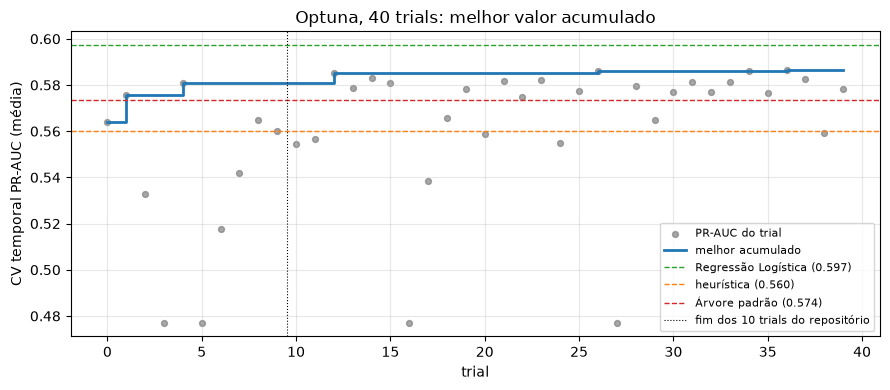

 number  value  melhor_acumulado
      0  0.564             0.564
      4  0.581             0.581
      9  0.560             0.581
     19  0.578             0.585
     29  0.565             0.586
     39  0.578             0.586
trials com PR-AUC abaixo da heurística: 14 | acima da Árvore padrão: 22 | acima da Regressão Logística: 0


In [10]:
r_lr, r_h = resultados[(ALVO, "regressao_logistica")], resultados[(ALVO, "heuristica_recorrencia")]
r_pad = resultados[(ALVO, "arvore_padrao")]
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(trials["number"], trials["value"], s=18, color="gray", alpha=.7, label="PR-AUC do trial")
ax.step(trials["number"], trials["melhor_acumulado"], where="post", color="C0", lw=2, label="melhor acumulado")
for r, nome, cor in [(r_lr, "Regressão Logística", "C2"), (r_h, "heurística", "C1"), (r_pad, "Árvore padrão", "C3")]:
    ax.axhline(r["cv_temporal_pr_auc_mean"], ls="--", lw=1, color=cor, label=f"{nome} ({r['cv_temporal_pr_auc_mean']:.3f})")
ax.axvline(9.5, color="k", lw=.8, ls=":", label="fim dos 10 trials do repositório")
ax.set(xlabel="trial", ylabel="CV temporal PR-AUC (média)", title="Optuna, 40 trials: melhor valor acumulado")
ax.legend(fontsize=8, loc="lower right")
salvar(fig, "optuna_melhor_acumulado.png")
print(trials[["number", "value", "melhor_acumulado"]].iloc[[0, 4, 9, 19, 29, n_feitos - 1]].to_string(index=False))
print("trials com PR-AUC abaixo da heurística:", int((trials["value"] < r_h["cv_temporal_pr_auc_mean"]).sum()),
      "| acima da Árvore padrão:", int((trials["value"] > r_pad["cv_temporal_pr_auc_mean"]).sum()),
      "| acima da Regressão Logística:", int((trials["value"] > r_lr["cv_temporal_pr_auc_mean"]).sum()))

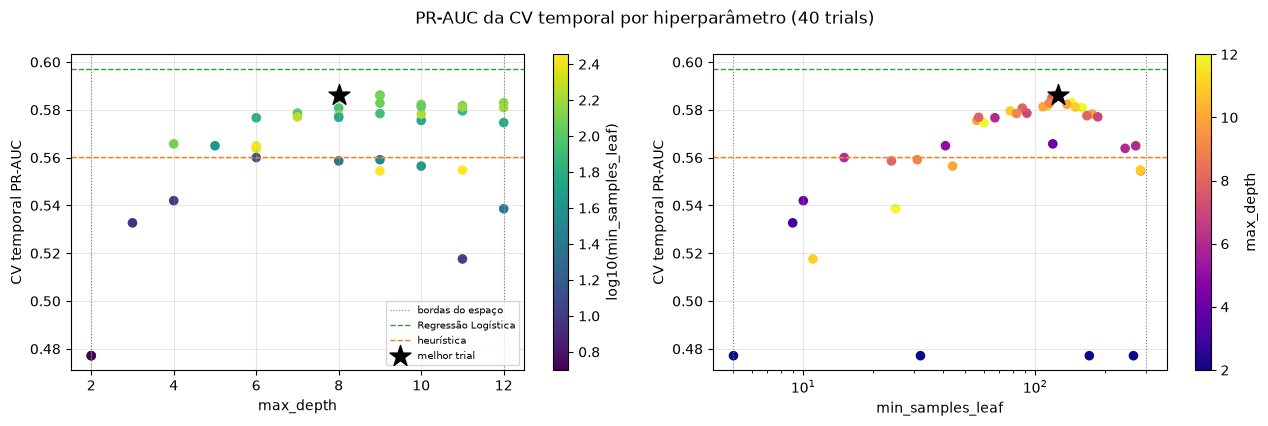

Spearman hiperparâmetro × PR-AUC: {'max_depth': 0.428, 'min_samples_leaf': 0.313}

posição do melhor valor no espaço (0 = borda de baixo, 1 = borda de cima; min_samples_leaf em escala log):
  max_depth = 8: 0.60
  min_samples_leaf = 125: 0.79

nos 10 melhores trials:
  max_depth: valores de 8 a 12 | posição de 0.60 a 1.00
  min_samples_leaf: valores de 108 a 149 | posição de 0.75 a 0.83

média do PR-AUC por max_depth (40 trials):
           count   mean    max
max_depth                     
2              4  0.477  0.477
3              1  0.533  0.533
4              2  0.554  0.566
5              1  0.565  0.565
6              4  0.566  0.577
7              2  0.578  0.579
8              6  0.578  0.586
9              6  0.575  0.586
10             5  0.575  0.582
11             5  0.563  0.582
12             4  0.569  0.583


In [11]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
sc = axs[0].scatter(trials["max_depth"], trials["value"], c=np.log10(trials["min_samples_leaf"]), cmap="viridis", s=35)
fig.colorbar(sc, ax=axs[0], label="log10(min_samples_leaf)")
sc = axs[1].scatter(trials["min_samples_leaf"], trials["value"], c=trials["max_depth"], cmap="plasma", s=35)
fig.colorbar(sc, ax=axs[1], label="max_depth")
for ax, hp in zip(axs, ["max_depth", "min_samples_leaf"]):
    lo, hi = BORDAS[hp]
    ax.axvline(lo, color="gray", lw=.8, ls=":")
    ax.axvline(hi, color="gray", lw=.8, ls=":", label="bordas do espaço")
    ax.axhline(r_lr["cv_temporal_pr_auc_mean"], color="C2", ls="--", lw=1, label="Regressão Logística")
    ax.axhline(r_h["cv_temporal_pr_auc_mean"], color="C1", ls="--", lw=1, label="heurística")
    ax.scatter([params_melhor[hp]], [melhor.value], marker="*", s=250, color="k", zorder=5, label="melhor trial")
    ax.set(xlabel=hp, ylabel="CV temporal PR-AUC")
axs[1].set_xscale("log")
axs[0].legend(fontsize=7, loc="lower right")
fig.suptitle("PR-AUC da CV temporal por hiperparâmetro (40 trials)")
salvar(fig, "optuna_pr_auc_por_hiperparametro.png")
print("Spearman hiperparâmetro × PR-AUC:",
      {hp: round(float(trials[hp].corr(trials["value"], method="spearman")), 3) for hp in BORDAS})


def posicao(hp, v):
    lo, hi = BORDAS[hp]
    if hp == "min_samples_leaf":  # escala log, como no espaço
        return (np.log(v) - np.log(lo)) / (np.log(hi) - np.log(lo))
    return (v - lo) / (hi - lo)


print("\nposição do melhor valor no espaço (0 = borda de baixo, 1 = borda de cima; min_samples_leaf em escala log):")
for hp in BORDAS:
    print(f"  {hp} = {params_melhor[hp]}: {posicao(hp, params_melhor[hp]):.2f}")
top10 = trials.nlargest(10, "value")
print("\nnos 10 melhores trials:")
for hp in BORDAS:
    pos = posicao(hp, top10[hp])
    print(f"  {hp}: valores de {top10[hp].min()} a {top10[hp].max()} | posição de {pos.min():.2f} a {pos.max():.2f}")
print("\nmédia do PR-AUC por max_depth (40 trials):")
print(trials.groupby("max_depth")["value"].agg(["count", "mean", "max"]).round(4).to_string())

**Leitura.**

- **Custo:** os 40 trials levaram 27,4 s (mediana de 0,67 s por trial), muito abaixo do limite de
  30 min. As 40 combinações de (`max_depth`, `min_samples_leaf`) são todas diferentes.
- **Melhor trial: #36, `max_depth=8` e `min_samples_leaf=125`**, com PR-AUC de 0,5864 na CV temporal
  e de 0,645 na validação de 2023 (só reportada). Os três melhores trials empatam em 0,586
  (`8`/`125`, `9`/`123`, `9`/`124`), e os 10 melhores ficam entre 0,581 e 0,586: o platô é largo.
- **O melhor acumulado** chega a 0,581 já no trial 4, a 0,585 até o trial 19 e a 0,586 até o trial 29.
  Depois disso não muda.
- **Nenhum dos 40 trials passa da Regressão Logística** (0,597). 22 ficam acima da árvore padrão
  (0,574), e 14 ficam abaixo da heurística (0,560). As profundidades rasas puxam a média para baixo:
  com `max_depth=2`, a média dos trials é 0,477.
- **Bordas do espaço: o melhor ponto não encosta.** `max_depth=8` fica a 0,60 do caminho entre 2 e 12,
  e `min_samples_leaf=125` fica a 0,79 entre 5 e 300 em escala log. Nos 10 melhores, o
  `min_samples_leaf` fica numa faixa estreita (108 a 149, posição de 0,75 a 0,83). Já o `max_depth`
  vai de 8 a 12, e um deles (trial 14) usa 12, a borda de cima. A seção 6 mostra por que isso
  não importa: com folhas de ~125 linhas, a árvore quase não cresce depois da profundidade 8, e o
  PR-AUC fica igual até sem limite de profundidade. Não há sinal de que valha ampliar o espaço, e ele
  não foi ampliado.
- O Spearman entre o hiperparâmetro e o PR-AUC é +0,43 para `max_depth` e +0,31 para
  `min_samples_leaf`.

### Valeu ampliar de 10 para 40 trials?

O repositório usa 10 trials (`T.N_TRIALS`, seção 17.5). Rodo um estudo separado de 10 trials, com
a mesma semente e o mesmo objetivo, para comparar com os 40. A validação de 2023 dos dois melhores
é só reportada, sem registro no MLflow.

In [12]:
estudo10, tempo10 = estudar(10)
params10 = dict(estudo10.best_params)
m10 = em_validacao(yv, montar_pipeline(features, MODELO, **params10).fit(Xtr, ytr).predict_proba(Xv)[:, 1], tri_v)
comparacao_busca = pd.DataFrame({
    "10 trials (padrão do repositório)": {"tempo (s)": tempo10, "melhor trial": estudo10.best_trial.number,
                                          "CV temporal PR-AUC": estudo10.best_value, "Val PR-AUC": m10["pr_auc"],
                                          "Val Precisão@100": m10["precisao_at_100"], "params": params10},
    "40 trials": {"tempo (s)": tempo_busca, "melhor trial": melhor.number, "CV temporal PR-AUC": melhor.value,
                  "Val PR-AUC": m_otim["pr_auc"], "Val Precisão@100": m_otim["precisao_at_100"], "params": params_melhor},
}).T
print("os 10 primeiros trials dos 40 coincidem com o estudo de 10:",
      np.allclose(trials["value"].iloc[:10], [t.value for t in estudo10.trials]))
print(f"ganho de CV temporal PR-AUC com 40 trials: {melhor.value - estudo10.best_value:+.4f} "
      f"(desvio entre folds do melhor: {extras_otim['cv_temporal_pr_auc_std']:.4f})")
print(f"tempo: 40 trials {tempo_busca:.1f} s | 10 trials {tempo10:.1f} s | razão {tempo_busca / tempo10:.1f}×")
comparacao_busca

os 10 primeiros trials dos 40 coincidem com o estudo de 10: True
ganho de CV temporal PR-AUC com 40 trials: +0.0057 (desvio entre folds do melhor: 0.0244)
tempo: 40 trials 27.4 s | 10 trials 6.7 s | razão 4.1×


,tempo (s),melhor trial,CV temporal PR-AUC,Val PR-AUC,Val Precisão@100,params
10 trials (padrão do repositório),6.71,4,0.581,0.634,0.9,"{'max_depth': 8, 'min_samples_leaf': 88}"
40 trials,27.362,36,0.586,0.645,0.9,"{'max_depth': 8, 'min_samples_leaf': 125}"


**Leitura: ampliar para 40 trials rendeu pouco, mas custou pouco.** Com a mesma semente, os 10
primeiros trials dos 40 são idênticos ao estudo de 10. O estudo de 10 acha o seu melhor no trial 4
(`max_depth=8`, `min_samples_leaf=88`), com 0,581 na CV temporal e 0,634 na validação. Os 40 trials
ficam com a mesma profundidade e uma folha mínima maior (125). Eles ganham **+0,0057** na CV, bem abaixo do
desvio entre folds do melhor (0,024), e +0,011 na validação de 2023 (0,645 contra 0,634).
A precisão@100 é a mesma (0,900). O tempo foi 4,1 vezes maior (27,4 s contra 6,7 s), mas a busca
inteira leva menos de meio minuto. Ao contrário do MLP, aqui a configuração de 40 trials também é
melhor na validação, mas nenhuma das duas alcança a Regressão Logística.

## 6. Viés × variância

Duas varreduras, cada uma mudando um hiperparâmetro e deixando o outro fixo na melhor configuração.
Para cada ponto: PR-AUC no próprio treino (ajuste no treino inteiro), PR-AUC da CV temporal (média
± desvio entre folds), PR-AUC na validação de 2023 (só reportado), nº de folhas e profundidade real.
A distância treino − CV temporal mede a variância (sobreajuste); o nível da CV temporal, o viés.

- `max_depth` de 2 a 12 (o espaço) e `None` (sem limite), este **só exploratório**, fora do espaço
  da busca. Como contraste, a mesma varredura com `min_samples_leaf=5` (a borda de baixo do espaço),
  em que a folha mínima quase não segura o crescimento.
- `min_samples_leaf` de 5 a 300 (o espaço). Como contraste exploratório, a mesma varredura com
  `max_depth=None`.

varreduras de max_depth em 24.0 s


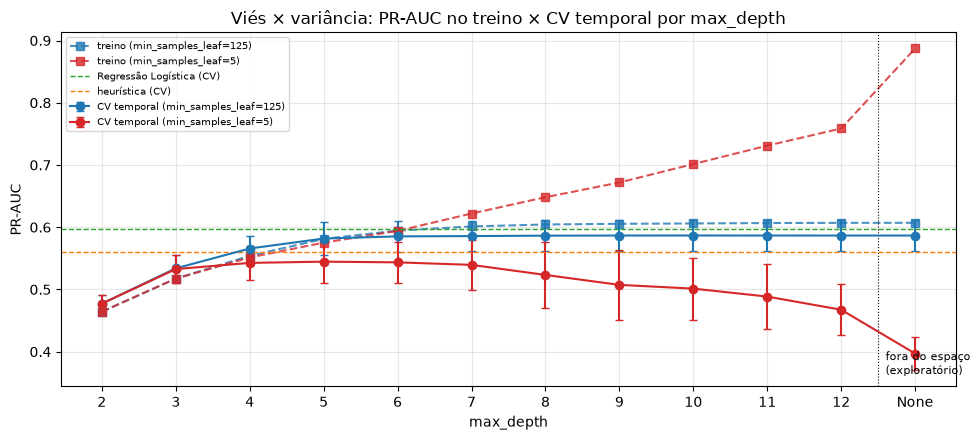

min_samples_leaf=125 (melhor):


,treino PR-AUC,CV temporal PR-AUC,desvio entre folds,Val PR-AUC,folhas,profundidade real,treino − CV
max_depth,,,,,,,
2,0.464,0.477,0.013,0.552,4,2,-1.290e-02
3,0.517,0.534,0.021,0.589,8,3,-1.650e-02
4,0.554,0.566,0.021,0.614,16,4,-1.180e-02
5,0.581,0.582,0.026,0.629,27,5,-6.000e-04
6,0.595,0.585,0.025,0.639,38,6,9.200e-03
7,0.601,0.586,0.024,0.645,49,7,1.550e-02
8,0.604,0.586,0.024,0.645,59,8,1.800e-02
9,0.606,0.587,0.024,0.645,67,9,1.880e-02
10,0.606,0.587,0.024,0.646,72,10,1.940e-02


min_samples_leaf=5 (borda de baixo do espaço):


,treino PR-AUC,CV temporal PR-AUC,desvio entre folds,Val PR-AUC,folhas,profundidade real,treino − CV
max_depth,,,,,,,
2,0.464,0.477,0.013,0.552,4,2,-0.013
3,0.517,0.533,0.022,0.589,8,3,-0.015
4,0.551,0.543,0.027,0.609,16,4,0.009
5,0.575,0.545,0.035,0.617,31,5,0.030
6,0.594,0.543,0.033,0.615,56,6,0.051
7,0.622,0.539,0.041,0.610,88,7,0.083
8,0.648,0.523,0.052,0.597,136,8,0.125
9,0.672,0.507,0.056,0.581,185,9,0.165
10,0.702,0.501,0.050,0.569,251,10,0.200


min_samples_leaf=125: pico da CV em max_depth=10 (0.5867) | treino − CV de -0.0165 a +0.0204
min_samples_leaf=5: pico da CV em max_depth=5 (0.5447) | treino − CV de -0.0153 a +0.2913


In [13]:
def varrer(**mudanca):
    p = montar_pipeline(features, MODELO, **{**params_melhor, **mudanca})
    cv = _cv(p, Xtr, ytr, folds)
    aj = clone(p).fit(Xtr, ytr)
    arv = aj.named_steps["modelo"]
    return {"treino PR-AUC": average_precision_score(ytr, aj.predict_proba(Xtr)[:, 1]),
            "CV temporal PR-AUC": cv["cv_temporal_pr_auc_mean"], "desvio entre folds": cv["cv_temporal_pr_auc_std"],
            "Val PR-AUC": average_precision_score(yv, aj.predict_proba(Xv)[:, 1]),
            "folhas": arv.get_n_leaves(), "profundidade real": arv.get_depth()}


def grafico_varredura(ax, x, df, rotulo, cor):
    ax.plot(x, df["treino PR-AUC"], "s--", color=cor, alpha=.8, label=f"treino ({rotulo})")
    ax.errorbar(x, df["CV temporal PR-AUC"], yerr=df["desvio entre folds"], marker="o", color=cor, capsize=3,
                label=f"CV temporal ({rotulo})")


PROFUNDIDADES = list(range(2, 13)) + [None]
ROT_PROF = [str(d) for d in PROFUNDIDADES]
t0 = time.time()
var_prof = pd.DataFrame([varrer(max_depth=d) for d in PROFUNDIDADES], index=pd.Index(ROT_PROF, name="max_depth"))
var_prof5 = pd.DataFrame([varrer(max_depth=d, min_samples_leaf=5) for d in PROFUNDIDADES],
                         index=pd.Index(ROT_PROF, name="max_depth"))
for v in (var_prof, var_prof5):
    v["treino − CV"] = v["treino PR-AUC"] - v["CV temporal PR-AUC"]
print(f"varreduras de max_depth em {time.time() - t0:.1f} s")

fig, ax = plt.subplots(figsize=(10, 4.5))
x = range(len(PROFUNDIDADES))
grafico_varredura(ax, x, var_prof, f"min_samples_leaf={params_melhor['min_samples_leaf']}", "C0")
grafico_varredura(ax, x, var_prof5, "min_samples_leaf=5", "C3")
ax.axhline(r_lr["cv_temporal_pr_auc_mean"], color="C2", ls="--", lw=1, label="Regressão Logística (CV)")
ax.axhline(r_h["cv_temporal_pr_auc_mean"], color="C1", ls="--", lw=1, label="heurística (CV)")
ax.axvline(len(PROFUNDIDADES) - 1.5, color="k", ls=":", lw=.8)
ax.text(len(PROFUNDIDADES) - 1.4, ax.get_ylim()[0] + .02, "fora do espaço\n(exploratório)", fontsize=8)
ax.set_xticks(list(x), ROT_PROF)
ax.set(xlabel="max_depth", ylabel="PR-AUC", title="Viés × variância: PR-AUC no treino × CV temporal por max_depth")
ax.legend(fontsize=7, loc="upper left")
salvar(fig, "vies_variancia_max_depth.png")
print(f"min_samples_leaf={params_melhor['min_samples_leaf']} (melhor):")
display(var_prof.round(4))
print("min_samples_leaf=5 (borda de baixo do espaço):")
display(var_prof5.round(4))
for nome, v in [(f"min_samples_leaf={params_melhor['min_samples_leaf']}", var_prof), ("min_samples_leaf=5", var_prof5)]:
    no_espaco = v.drop(index="None")
    print(f"{nome}: pico da CV em max_depth={no_espaco['CV temporal PR-AUC'].idxmax()} "
          f"({no_espaco['CV temporal PR-AUC'].max():.4f}) | treino − CV de {no_espaco['treino − CV'].min():+.4f} "
          f"a {no_espaco['treino − CV'].max():+.4f}")

varreduras de min_samples_leaf em 20.2 s


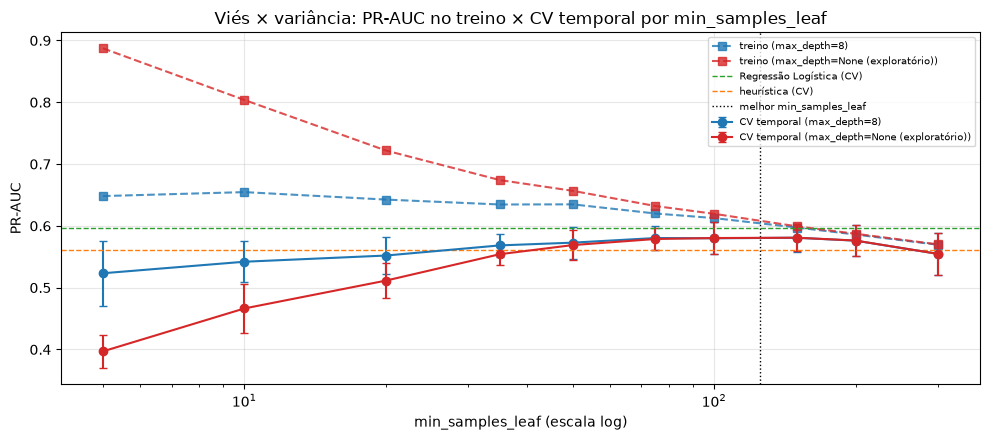

max_depth=8 (melhor):


,treino PR-AUC,CV temporal PR-AUC,desvio entre folds,Val PR-AUC,folhas,profundidade real,treino − CV
min_samples_leaf,,,,,,,
5,0.648,0.523,0.052,0.597,136,8,0.125
10,0.655,0.542,0.033,0.613,131,8,0.113
20,0.642,0.552,0.030,0.621,116,8,0.091
35,0.635,0.568,0.019,0.629,93,8,0.066
50,0.635,0.573,0.026,0.636,95,8,0.062
75,0.620,0.580,0.019,0.639,76,8,0.040
100,0.613,0.580,0.026,0.638,68,8,0.033
150,0.597,0.581,0.023,0.644,51,8,0.017
200,0.586,0.576,0.025,0.642,43,8,0.010


max_depth=None (exploratório):


,treino PR-AUC,CV temporal PR-AUC,desvio entre folds,Val PR-AUC,folhas,profundidade real,treino − CV
min_samples_leaf,,,,,,,
5,0.887,0.397,0.027,0.457,895,24,0.490
10,0.804,0.466,0.040,0.525,590,23,0.337
20,0.722,0.511,0.029,0.588,374,20,0.211
35,0.674,0.554,0.018,0.617,235,18,0.120
50,0.657,0.569,0.025,0.632,186,16,0.088
75,0.632,0.579,0.018,0.639,125,15,0.053
100,0.620,0.580,0.026,0.638,99,13,0.039
150,0.599,0.581,0.022,0.644,64,12,0.018
200,0.587,0.576,0.025,0.641,52,12,0.011


In [14]:
FOLHA_MIN = [5, 10, 20, 35, 50, 75, 100, 150, 200, 300]
t0 = time.time()
var_folha = pd.DataFrame([varrer(min_samples_leaf=m) for m in FOLHA_MIN], index=pd.Index(FOLHA_MIN, name="min_samples_leaf"))
var_folha_none = pd.DataFrame([varrer(min_samples_leaf=m, max_depth=None) for m in FOLHA_MIN],
                              index=pd.Index(FOLHA_MIN, name="min_samples_leaf"))
for v in (var_folha, var_folha_none):
    v["treino − CV"] = v["treino PR-AUC"] - v["CV temporal PR-AUC"]
print(f"varreduras de min_samples_leaf em {time.time() - t0:.1f} s")

fig, ax = plt.subplots(figsize=(10, 4.5))
grafico_varredura(ax, FOLHA_MIN, var_folha, f"max_depth={params_melhor['max_depth']}", "C0")
grafico_varredura(ax, FOLHA_MIN, var_folha_none, "max_depth=None (exploratório)", "C3")
ax.axhline(r_lr["cv_temporal_pr_auc_mean"], color="C2", ls="--", lw=1, label="Regressão Logística (CV)")
ax.axhline(r_h["cv_temporal_pr_auc_mean"], color="C1", ls="--", lw=1, label="heurística (CV)")
ax.axvline(params_melhor["min_samples_leaf"], color="k", ls=":", lw=1, label="melhor min_samples_leaf")
ax.set(xscale="log", xlabel="min_samples_leaf (escala log)", ylabel="PR-AUC",
       title="Viés × variância: PR-AUC no treino × CV temporal por min_samples_leaf")
ax.legend(fontsize=7, loc="upper right")
salvar(fig, "vies_variancia_min_samples_leaf.png")
print(f"max_depth={params_melhor['max_depth']} (melhor):")
display(var_folha.round(4))
print("max_depth=None (exploratório):")
display(var_folha_none.round(4))

**Leitura (viés × variância).**

- **Com a folha mínima da melhor configuração (125), a profundidade só reduz o viés.** O PR-AUC da CV
  temporal sobe de 0,477 (`max_depth=2`, 4 folhas) para 0,582 (5) e 0,586 (7 e 8), e para de subir: de
  9 a 12 e sem limite (`None`), fica em 0,587. A folha mínima de 125 linhas trava o crescimento.
  Mesmo sem limite de profundidade, a árvore para com 81 folhas e profundidade 13. A distância
  treino − CV vai de −0,013 (profundidade 2) a +0,020 (12 e `None`), sem sobreajuste relevante.
- **Com folhas de 5 linhas (borda de baixo do espaço), o sobreajuste começa na profundidade 6.** A CV
  temporal atinge o pico em `max_depth=5` (0,545) e cai a partir daí: 0,543 (6), 0,523 (8), 0,467 (12)
  e 0,397 sem limite. Ao mesmo tempo, o PR-AUC do treino sobe de 0,575 (5) para 0,759 (12) e 0,887
  (`None`, 895 folhas, profundidade 24). A distância treino − CV passa de +0,030 em 5 para +0,291 em 12
  e +0,490 sem limite. O desvio entre folds também cresce, de 0,035 (5) para 0,052 a 0,056 (8 e 9). A
  validação de 2023 segue o mesmo desenho (0,617 em 5, 0,526 em 12, 0,457 sem limite).
- **Quem regulariza a árvore é o `min_samples_leaf`, não o `max_depth`.** Com `max_depth=8`, folhas de 5
  linhas dão CV de 0,523 e distância treino − CV de +0,125 (variância). A CV sobe até 0,580 com 75 e 100
  linhas e chega ao máximo da varredura, 0,581, com 150. Com 200 e 300 linhas, cai para 0,576 e 0,555,
  e o treino também cai (0,569 com 300): é o lado do viés. **O sobreajuste fica visível abaixo de ~75
  linhas por folha.** Com 50 linhas, a distância treino − CV já é de +0,062 e a CV cai para 0,573. Com
  20, as duas são +0,091 e 0,552.
- **Sem limite de profundidade (exploratório)**, a curva do `min_samples_leaf` coincide com a de
  `max_depth=8` a partir de 100 linhas por folha (0,580, 0,581, 0,576 e 0,555). Com folhas pequenas, a
  árvore sem limite despenca (0,397 com 5 linhas).

### Curva de aprendizado da melhor configuração

`metricas.curva_aprendizado` nos 4 folds temporais (fatias de 33%, 66% e 100% do treino de cada
fold), e o PR-AUC no próprio treino × CV temporal × validação 2023 dos modelos até aqui.

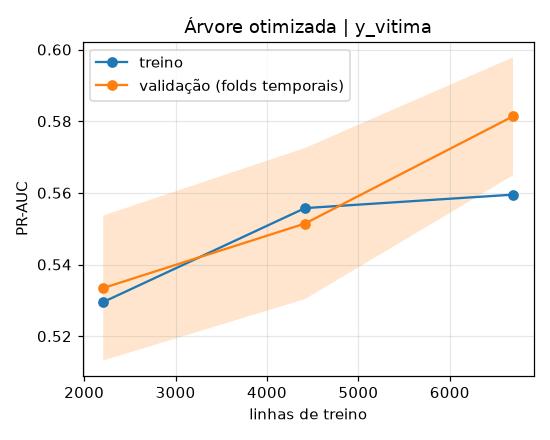

,linhas de treino,treino (média),validação dos folds (média),validação (desvio),treino − validação
0,2208,0.530,0.533,0.020,-0.004
1,4416,0.556,0.551,0.021,0.004
2,6692,0.560,0.581,0.016,-0.022


In [15]:
titulo_otim = f"Árvore otimizada | {ALVO}"
metricas.curva_aprendizado(clone(pipe_otim), Xtr, ytr, folds, FIG / "curva_aprendizado.png", titulo_otim)
display(Image(FIG / "curva_aprendizado.png"))
# os mesmos números da figura, para a leitura
tam, s_tr, s_va = learning_curve(clone(pipe_otim), Xtr, ytr, cv=folds, train_sizes=[0.33, 0.66, 1.0],
                                 scoring="average_precision", n_jobs=1)
pd.DataFrame({"linhas de treino": tam, "treino (média)": s_tr.mean(1), "validação dos folds (média)": s_va.mean(1),
              "validação (desvio)": s_va.std(1), "treino − validação": s_tr.mean(1) - s_va.mean(1)}).round(3)

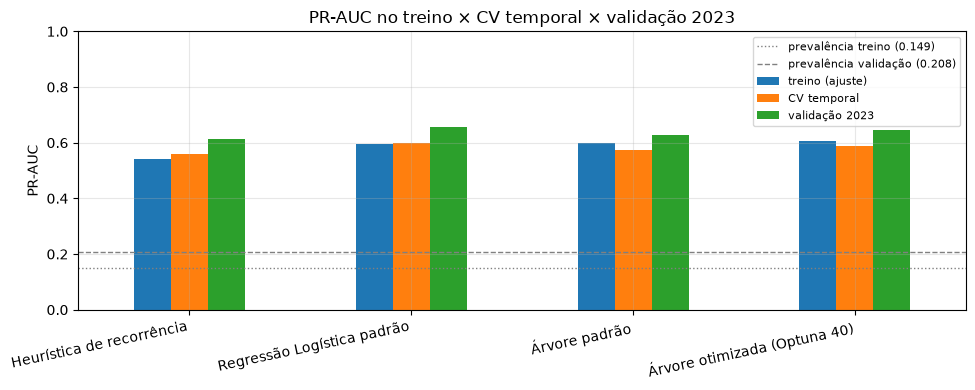

,treino (ajuste),CV temporal,validação 2023,treino − CV temporal
Heurística de recorrência,0.540,0.560,0.614,-0.020
Regressão Logística padrão,0.595,0.597,0.658,-0.002
Árvore padrão,0.599,0.574,0.628,0.026
Árvore otimizada (Optuna 40),0.604,0.586,0.645,0.018


In [16]:
def treino_val(nome, pipe=None, score_fn=None):
    r = resultados[(ALVO, nome)]
    if pipe is not None:
        treino = average_precision_score(ytr, clone(pipe).fit(Xtr, ytr).predict_proba(Xtr)[:, 1])
    else:
        treino = average_precision_score(ytr, score_fn(partes["treino"]))
    return {"treino (ajuste)": treino, "CV temporal": r["cv_temporal_pr_auc_mean"], "validação 2023": r["val_pr_auc"]}


tv = pd.DataFrame({
    NOMES["heuristica_recorrencia"]: treino_val("heuristica_recorrencia", score_fn=score_heuristica),
    NOMES["regressao_logistica"]: treino_val("regressao_logistica", montar_pipeline(features, "regressao_logistica")),
    NOMES["arvore_padrao"]: treino_val("arvore_padrao", pipe_padrao),
    NOMES["arvore_otimizada"]: treino_val("arvore_otimizada", pipe_otim),
}).T
tv["treino − CV temporal"] = tv["treino (ajuste)"] - tv["CV temporal"]
fig, ax = plt.subplots(figsize=(10, 4))
tv.iloc[:, :3].plot.bar(ax=ax)
ax.axhline(ytr.mean(), color="gray", ls=":", lw=1, label=f"prevalência treino ({ytr.mean():.3f})")
ax.axhline(yv.mean(), color="gray", ls="--", lw=1, label=f"prevalência validação ({yv.mean():.3f})")
ax.set(ylabel="PR-AUC", ylim=(0, 1), title="PR-AUC no treino × CV temporal × validação 2023")
ax.legend(fontsize=8, loc="upper right")
plt.setp(ax.get_xticklabels(), rotation=12, ha="right")
salvar(fig, "pr_auc_treino_validacao.png")
tv.round(3)

**Leitura da curva de aprendizado.** O `learning_curve` usa como teto o treino do menor fold
(2021Q1–2021Q4, 6.692 linhas). Com 33%, 66% e 100% dele, o PR-AUC na validação dos folds sobe de
0,533 para 0,551 e 0,581, e a curva não achata. Mais dados ainda ajudam a árvore. Treino e validação
andam juntos, com distância de −0,004, +0,004 e −0,022: com folhas de 125 linhas, a árvore está
limitada por viés, não por variância.

**PR-AUC no treino × CV temporal × validação.** A árvore otimizada se ajusta ao treino um pouco mais
que a Regressão Logística (0,604 contra 0,595) e generaliza menos (CV de 0,586 contra 0,597). A
distância treino − CV é de +0,018 na otimizada, +0,026 na padrão, −0,002 na Regressão Logística e
−0,020 na heurística. O problema da árvore não é sobreajuste: com o mesmo nível de ajuste, uma função
em degraus de 59 folhas ordena os locais pior que uma combinação linear de todas as colunas. A
validação de 2023 fica acima da CV em todos (prevalência de 0,208 contra 0,149).

### Estabilidade: PR-AUC por fold temporal

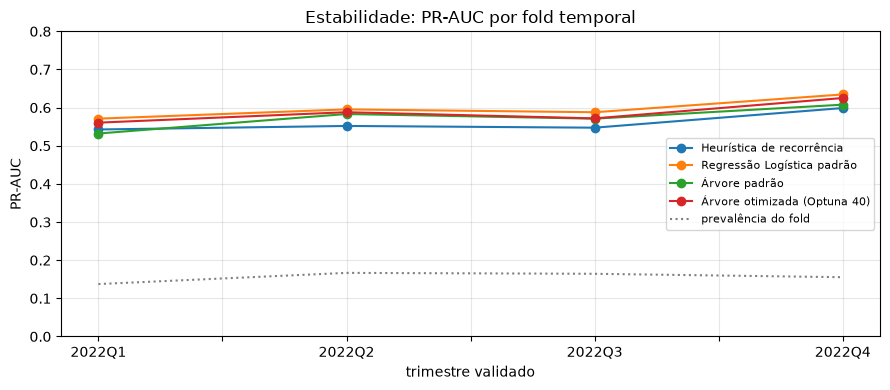

Árvore otimizada − Regressão Logística, por fold: {'2022Q1': -0.0105, '2022Q2': -0.0074, '2022Q3': -0.0161, '2022Q4': -0.0093}
Árvore otimizada − heurística, por fold: {'2022Q1': 0.0179, '2022Q2': 0.036, '2022Q3': 0.0244, '2022Q4': 0.0263}


,Heurística de recorrência,Regressão Logística padrão,Árvore padrão,Árvore otimizada (Optuna 40),prevalência do fold
2022Q1,0.543,0.571,0.532,0.561,0.137
2022Q2,0.552,0.595,0.583,0.588,0.167
2022Q3,0.547,0.588,0.571,0.572,0.164
2022Q4,0.599,0.635,0.608,0.625,0.155
média,0.560,0.597,0.574,0.586,0.156
desvio (ddof=0),0.023,0.023,0.027,0.024,0.012


In [17]:
folds_df[NOMES["arvore_otimizada"]] = por_fold(pipe_otim)
folds_df = folds_df[[NOMES[n] for n in ["heuristica_recorrencia", "regressao_logistica", "arvore_padrao", "arvore_otimizada"]]
                    + ["prevalência do fold"]]
fig, ax = plt.subplots(figsize=(9, 4))
folds_df.iloc[:, :4].plot(ax=ax, marker="o")
folds_df["prevalência do fold"].plot(ax=ax, color="gray", ls=":", label="prevalência do fold")
ax.set(xlabel="trimestre validado", ylabel="PR-AUC", ylim=(0, .8), title="Estabilidade: PR-AUC por fold temporal")
ax.legend(fontsize=8)
salvar(fig, "pr_auc_por_fold.png")
dif_fold = folds_df[NOMES["arvore_otimizada"]] - folds_df[NOMES["regressao_logistica"]]
print("Árvore otimizada − Regressão Logística, por fold:", dif_fold.round(4).to_dict())
print("Árvore otimizada − heurística, por fold:",
      (folds_df[NOMES["arvore_otimizada"]] - folds_df[NOMES["heuristica_recorrencia"]]).round(4).to_dict())
tabela_folds = folds_df.copy()
tabela_folds.loc["média"] = folds_df.mean()
tabela_folds.loc["desvio (ddof=0)"] = folds_df.std(ddof=0)
tabela_folds.round(3)

**Leitura.** Os quatro modelos sobem e descem juntos. Todos têm o maior PR-AUC em 2022Q4, e a
árvore otimizada vai de 0,561 (2022Q1) a 0,625 (2022Q4). O desvio entre folds da árvore otimizada
(0,024) é o mesmo dos pisos (0,023). Na comparação pareada, ela **perde da Regressão Logística nos
quatro folds** (−0,011, −0,007, −0,016 e −0,009) e **ganha da heurística nos quatro** (+0,018 a
+0,036). A desvantagem média para a Regressão Logística (−0,011) é menor que o desvio entre folds,
mas o sinal é o mesmo em todos os folds. Como a semente não muda a CV (seção 8), o sinal consistente
pesa mais do que pesaria num modelo com ruído de semente.

## 7. Empates no score

O score da árvore é o valor da folha (a proporção ponderada de positivos do treino que caiu nela).
Todas as linhas de uma folha recebem o mesmo score, então a árvore só produz tantos valores
distintos quanto folhas. O `metricas.no_topo` pega os k maiores com `nlargest(keep="first")`: se o
50º colocado de um trimestre está numa folha com mais linhas do que vagas restantes, quem entra no
top-50 é decidido pela **ordem das linhas na tabela**, não pelo modelo.

Para cada trimestre de 2023 e para k = 50 e 100: o score do k-ésimo colocado, quantas linhas estão
acima dele, quantas vagas sobram, quantas linhas empatam no corte e quantas delas são positivas.
Com isso, o Recall@k tem três versões: o **pior caso** (os empatados negativos entram primeiro), o
**melhor caso** (os positivos entram primeiro) e o **esperado** com desempate ao acaso
(vagas × positivos empatados ÷ empatados). O número que vai para a tabela é o do `no_topo`, que cai
em algum ponto entre os dois extremos.

In [18]:
def empates_no_corte(y, score, trimestre, k):
    df = pd.DataFrame({"y": np.asarray(y), "score": np.asarray(score, dtype=float), "tri": np.asarray(trimestre)})
    linhas = []
    for t, g in df.groupby("tri"):
        s_k = g.sort_values("score", ascending=False, kind="stable")["score"].iloc[k - 1]
        acima, emp = g[g["score"] > s_k], g[g["score"] == s_k]
        vagas, a, n_t, p_t, pos = k - len(acima), acima["y"].sum(), len(emp), emp["y"].sum(), g["y"].sum()
        linhas.append({"trimestre": t, f"score do {k}º": s_k, "linhas acima do corte": len(acima), "vagas no corte": vagas,
                       "linhas empatadas no corte": n_t, "positivos entre os empatados": p_t, "positivos do trimestre": pos,
                       "acertos (no_topo)": g.nlargest(k, "score")["y"].sum(),
                       "acertos pior caso": a + max(0, vagas - (n_t - p_t)), "acertos melhor caso": a + min(vagas, p_t),
                       "acertos esperados": a + vagas * p_t / n_t})
    return pd.DataFrame(linhas).set_index("trimestre")


def recall_com_empates(y, score, trimestre, k):
    e = empates_no_corte(y, score, trimestre, k)
    e = e[e["positivos do trimestre"] > 0]
    versoes = {"no_topo": "acertos (no_topo)", "pior caso": "acertos pior caso", "esperado": "acertos esperados",
               "melhor caso": "acertos melhor caso"}
    return {f"Recall@{k} ({v})": float((e[c] / e["positivos do trimestre"]).mean()) for v, c in versoes.items()} | {
        f"Precisão@{k} (no_topo)": float((e["acertos (no_topo)"] / k).mean()),
        f"linhas empatadas no corte do {k}º (média por trimestre)": float(e["linhas empatadas no corte"].mean())}


prep_otim = pipe_otim.named_steps["prep"]
folha_v = arv_otim.apply(prep_otim.transform(Xv))
print(f"Árvore otimizada: {arv_otim.get_n_leaves()} folhas | folhas que recebem alguma linha da validação: "
      f"{len(np.unique(folha_v))} | scores distintos na validação: {scores_distintos(score_otim)} de {len(Xv)} linhas")
print(f"Árvore padrão: {arv_padrao.get_n_leaves()} folhas | scores distintos na validação: {scores_distintos(score_padrao)}")
tam_folha = pd.Series(folha_v).value_counts()
print(f"linhas da validação por folha: mediana {tam_folha.median():.0f} | máx {tam_folha.max()} | "
      f"folha com mais linhas tem score {score_otim[folha_v == tam_folha.index[0]][0]:.3f}")
for k in metricas.KS:
    print(f"\nÁrvore otimizada, corte no {k}º colocado de cada trimestre (validação 2023):")
    display(empates_no_corte(yv, score_otim, tri_v, k).round(3))

Árvore otimizada: 59 folhas | folhas que recebem alguma linha da validação: 59 | scores distintos na validação: 58 de 6692 linhas
Árvore padrão: 48 folhas | scores distintos na validação: 44
linhas da validação por folha: mediana 90 | máx 605 | folha com mais linhas tem score 0.203

Árvore otimizada, corte no 50º colocado de cada trimestre (validação 2023):


,score do 50º,linhas acima do corte,vagas no corte,linhas empatadas no corte,positivos entre os empatados,positivos do trimestre,acertos (no_topo),acertos pior caso,acertos melhor caso,acertos esperados
trimestre,,,,,,,,,,
2023Q1,0.97,25,25,25,22,269,46,46,46,46.000
2023Q2,0.97,25,25,32,31,371,49,49,50,49.219
2023Q3,0.97,38,12,31,30,391,49,48,49,48.613
2023Q4,0.97,45,5,38,36,361,48,46,48,47.737



Árvore otimizada, corte no 100º colocado de cada trimestre (validação 2023):


,score do 100º,linhas acima do corte,vagas no corte,linhas empatadas no corte,positivos entre os empatados,positivos do trimestre,acertos (no_topo),acertos pior caso,acertos melhor caso,acertos esperados
trimestre,,,,,,,,,,
2023Q1,0.901,91,9,17,14,269,84,83,86,84.412
2023Q2,0.901,97,3,13,12,371,92,92,93,92.769
2023Q3,0.901,99,1,10,7,391,92,92,93,92.700
2023Q4,0.901,92,8,8,5,361,92,92,92,92.000


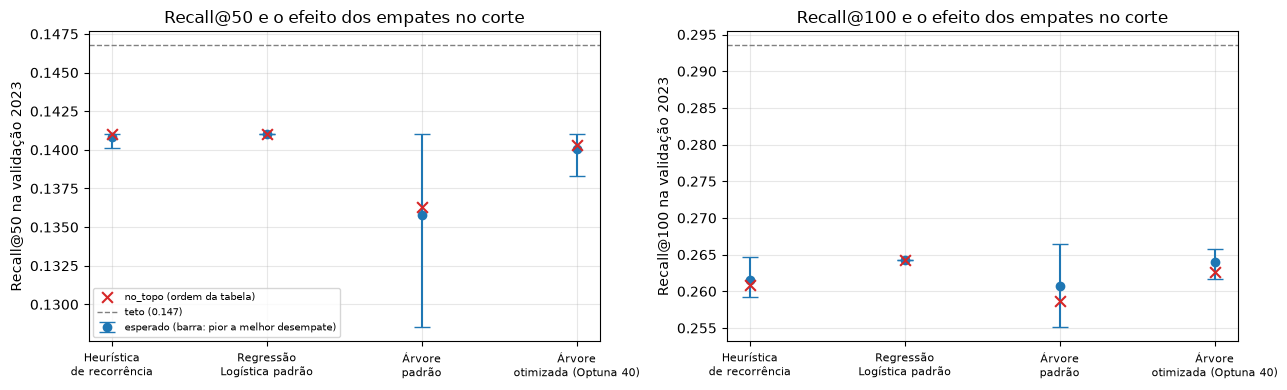

,Heurística de recorrência,Regressão Logística padrão,Árvore padrão,Árvore otimizada (Optuna 40)
scores distintos,1.540e+02,6684.000,44.000,58.000
Recall@50 (no_topo),1.410e-01,0.141,0.136,0.140
Recall@50 (pior caso),1.401e-01,0.141,0.129,0.138
Recall@50 (esperado),1.408e-01,0.141,0.136,0.140
Recall@50 (melhor caso),1.410e-01,0.141,0.141,0.141
Precisão@50 (no_topo),9.650e-01,0.965,0.935,0.960
linhas empatadas no corte do 50º (média por trimestre),3.500e+00,1.000,24.500,31.500
Recall@100 (no_topo),2.608e-01,0.264,0.259,0.263
Recall@100 (pior caso),2.592e-01,0.264,0.255,0.262
Recall@100 (esperado),2.616e-01,0.264,0.261,0.264


In [19]:
score_lr = clone(montar_pipeline(features, "regressao_logistica")).fit(Xtr, ytr).predict_proba(Xv)[:, 1]
comparacao_empates = {}
for nome, s in [(NOMES["heuristica_recorrencia"], score_heuristica(partes["validacao"]).to_numpy()),
                (NOMES["regressao_logistica"], score_lr), (NOMES["arvore_padrao"], score_padrao),
                (NOMES["arvore_otimizada"], score_otim)]:
    comparacao_empates[nome] = {"scores distintos": scores_distintos(s),
                                **recall_com_empates(yv, s, tri_v, 50), **recall_com_empates(yv, s, tri_v, 100)}
comparacao_empates = pd.DataFrame(comparacao_empates).T
for k in metricas.KS:
    comparacao_empates[f"amplitude Recall@{k} (melhor − pior)"] = (comparacao_empates[f"Recall@{k} (melhor caso)"]
                                                                   - comparacao_empates[f"Recall@{k} (pior caso)"])

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, k in zip(axs, metricas.KS):
    c = comparacao_empates
    ax.errorbar(range(len(c)), c[f"Recall@{k} (esperado)"],
                yerr=[c[f"Recall@{k} (esperado)"] - c[f"Recall@{k} (pior caso)"],
                      c[f"Recall@{k} (melhor caso)"] - c[f"Recall@{k} (esperado)"]],
                fmt="o", capsize=6, label="esperado (barra: pior a melhor desempate)")
    ax.scatter(range(len(c)), c[f"Recall@{k} (no_topo)"], marker="x", s=60, color="C3", zorder=5,
               label="no_topo (ordem da tabela)")
    ax.axhline(TETO[(ALVO, k)], color="gray", ls="--", lw=1, label=f"teto ({TETO[(ALVO, k)]:.3f})")
    ax.set_xticks(range(len(c)), [n.replace(" ", "\n", 1) for n in c.index], fontsize=8)
    ax.set(ylabel=f"Recall@{k} na validação 2023", title=f"Recall@{k} e o efeito dos empates no corte")
axs[0].legend(fontsize=7, loc="lower left")
salvar(fig, "empates_recall_at_k.png")
comparacao_empates.T.round(4)

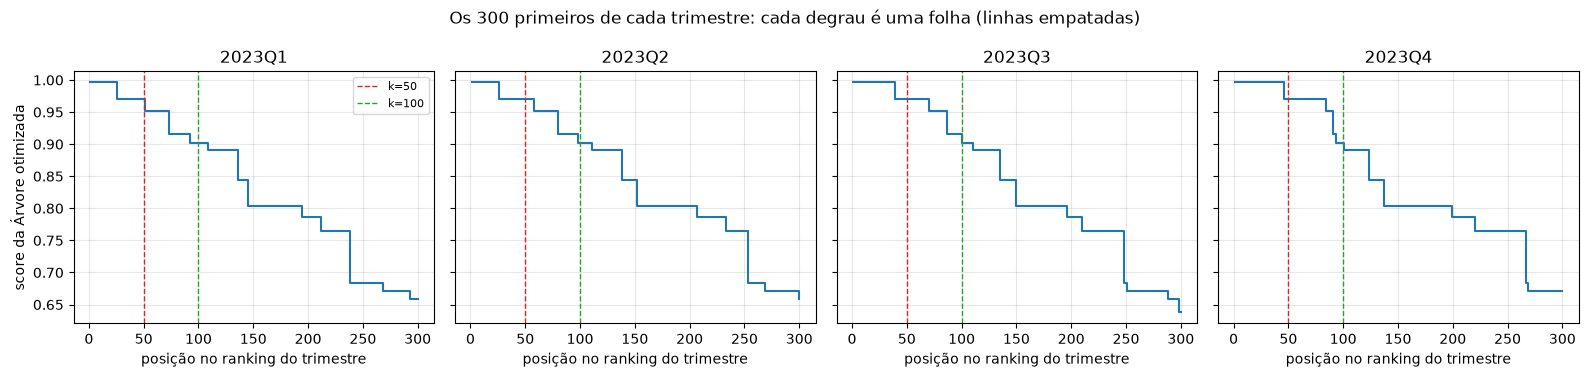

In [20]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (t, g) in zip(axs, pd.DataFrame({"score": score_otim, "y": yv.to_numpy(), "tri": tri_v.to_numpy()}).groupby("tri")):
    s = np.sort(g["score"].to_numpy())[::-1][:300]
    ax.step(np.arange(1, len(s) + 1), s, where="post")
    for k, cor in zip(metricas.KS, ["C3", "C2"]):
        ax.axvline(k, color=cor, ls="--", lw=1, label=f"k={k}")
    ax.set(title=t, xlabel="posição no ranking do trimestre")
axs[0].set_ylabel("score da Árvore otimizada")
axs[0].legend(fontsize=8)
fig.suptitle("Os 300 primeiros de cada trimestre: cada degrau é uma folha (linhas empatadas)")
salvar(fig, "empates_degraus_score.png")

**Leitura: na árvore otimizada, os empates quase não mexem no Recall@50.**

- A árvore otimizada tem 59 folhas, e todas recebem linhas da validação. São 58 valores distintos de
  score nas 6.692 linhas, com mediana de 90 linhas por folha e máximo de 605 (uma folha de score
  0,203).
- **Corte no 50º.** Nos quatro trimestres de 2023, o 50º colocado cai na mesma folha (score 0,97). Ela
  tem de 25 a 38 linhas empatadas por trimestre, e quase todas são positivas: 22 de 25, 31 de 32, 30 de
  31 e 36 de 38. Por isso, a ordem entre os empatados muda no máximo 2 acertos num trimestre. O
  Recall@50 fica entre **0,138 (pior caso) e 0,141 (melhor caso)**, com 0,140 no `no_topo` e no
  desempate ao acaso. A amplitude é de 0,003.
- **Corte no 100º.** O 100º cai numa folha de score 0,901, com 8 a 17 empatados. O Recall@100 vai de
  0,262 a 0,266 (amplitude de 0,004).
- **Na árvore padrão, os empates pesam mais.** Em média, 24,5 linhas empatam no corte do 50º, e o
  Recall@50 vai de 0,129 a 0,141 (amplitude de 0,013). No melhor desempate ela chegaria ao 0,141 dos
  pisos. A diferença de Recall@50 da Tabela 1 (0,136 contra 0,141) cabe inteira na ordem dos
  empatados.
- **Comparação com o AdaBoost (PR #11).** Lá, o padrão tinha 4 scores distintos e metade das linhas
  empatada num só valor, e o Recall@k caía muito. Aqui, com 44 a 58 folhas e uma folha quase pura no
  corte, o efeito no Recall@50 de `y_vitima` é pequeno. A heurística também empata (154 valores, com
  amplitude de 0,0009), e a Regressão Logística não tem empates. **Isso vale para `y_vitima`.** No
  atropelamento (seção 12), os empates mudam muito o Recall@50.
- A figura dos degraus mostra os 300 primeiros de cada trimestre: cada degrau é uma folha, e as
  linhas tracejadas marcam k = 50 e k = 100.

## 8. Sensibilidade à semente

Com `max_features=None` (todas as colunas avaliadas em cada divisão), o `random_state` da árvore só
muda a **ordem** em que as colunas são examinadas. Ele só altera o resultado quando duas divisões
têm exatamente a mesma melhora de impureza (empate), e então decide qual delas fica. Treino a
melhor configuração com 5 sementes (42, 0, 1, 2, 3), sem registrar runs, e meço o PR-AUC na CV
temporal e na validação, o nº de folhas e se a árvore ajustada no treino inteiro é idêntica à da
semente 42 (mesmas colunas, mesmos cortes e mesmos scores na validação).

5 sementes em 4.9 s


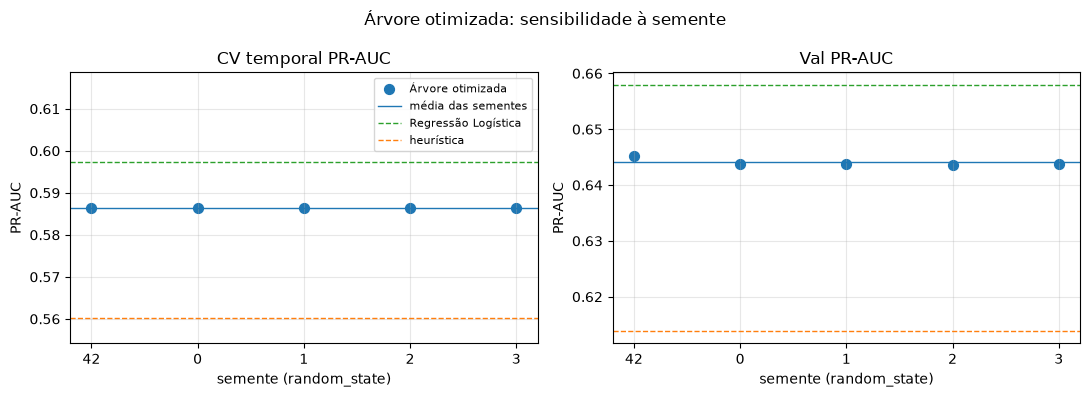

,CV temporal PR-AUC,desvio entre folds,Val PR-AUC,Val Recall@50,Val Precisão@100,folhas,árvore idêntica à da semente 42,scores da validação iguais aos da semente 42
semente,,,,,,,,
42,0.586,0.024,0.645,0.14,0.9,59,True,True
0,0.586,0.024,0.644,0.14,0.9,58,False,False
1,0.586,0.024,0.644,0.14,0.9,59,False,False
2,0.586,0.024,0.643,0.14,0.9,59,False,False
3,0.586,0.024,0.644,0.14,0.9,59,False,False


,média,desvio (ddof=1),amplitude (máx − mín)
CV temporal PR-AUC,0.586,0.000e+00,0.000
desvio entre folds,0.024,0.000e+00,0.000
Val PR-AUC,0.644,7.000e-04,0.002
Val Recall@50,0.140,0.000e+00,0.000
Val Precisão@100,0.900,0.000e+00,0.000
folhas,58.800,4.472e-01,1.000


In [21]:
SEMENTES = [42, 0, 1, 2, 3]
ref = arv_otim.tree_
linhas_s = []
t0 = time.time()
for s in SEMENTES:
    p = montar_pipeline(features, MODELO, **params_melhor, random_state=s)
    cv = _cv(p, Xtr, ytr, folds)
    ajustado = clone(p).fit(Xtr, ytr)
    a = ajustado.named_steps["modelo"].tree_
    sv = ajustado.predict_proba(Xv)[:, 1]
    mesma = (a.node_count == ref.node_count and np.array_equal(a.feature, ref.feature)
             and np.allclose(a.threshold, ref.threshold))
    linhas_s.append({"semente": s, "CV temporal PR-AUC": cv["cv_temporal_pr_auc_mean"],
                     "desvio entre folds": cv["cv_temporal_pr_auc_std"], "Val PR-AUC": average_precision_score(yv, sv),
                     "Val Recall@50": metricas.no_topo(yv, sv, tri_v, 50)[0],
                     "Val Precisão@100": metricas.no_topo(yv, sv, tri_v, 100)[1],
                     "folhas": ajustado.named_steps["modelo"].get_n_leaves(),
                     "árvore idêntica à da semente 42": mesma,
                     "scores da validação iguais aos da semente 42": bool(np.allclose(sv, score_otim))})
sementes = pd.DataFrame(linhas_s).set_index("semente")
print(f"5 sementes em {time.time() - t0:.1f} s")
num = sementes.select_dtypes("number")
resumo_s = pd.DataFrame({"média": num.mean(), "desvio (ddof=1)": num.std(), "amplitude (máx − mín)": num.max() - num.min()})

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, chave in [(axs[0], "CV temporal PR-AUC", "cv_temporal_pr_auc_mean"), (axs[1], "Val PR-AUC", "val_pr_auc")]:
    ax.scatter(range(len(SEMENTES)), sementes[col], s=50, color="C0", label="Árvore otimizada")
    ax.axhline(sementes[col].mean(), color="C0", lw=1, label="média das sementes")
    ax.axhline(r_lr[chave], color="C2", ls="--", lw=1, label="Regressão Logística")
    ax.axhline(r_h[chave], color="C1", ls="--", lw=1, label="heurística")
    ax.set_xticks(range(len(SEMENTES)), [str(s) for s in SEMENTES])
    ax.set(xlabel="semente (random_state)", ylabel="PR-AUC", title=col)
axs[0].legend(fontsize=8)
fig.suptitle("Árvore otimizada: sensibilidade à semente")
salvar(fig, "sensibilidade_semente.png")
display(sementes.round(4))
resumo_s.round(4)

**Leitura: a semente muda a árvore, mas quase não muda o resultado.**

- Nas 5 sementes, o PR-AUC da CV temporal é **idêntico** (0,586, desvio entre sementes 0), assim como
  o desvio entre folds (0,024), o Recall@50 (0,14) e a precisão@100 (0,90) da validação.
- Ajustadas no treino inteiro, as árvores das sementes 0, 1, 2 e 3 **não são idênticas** à da
  semente 42, e os scores da validação mudam. Logo, há divisões empatadas, e a semente escolhe entre
  elas. O efeito é pequeno: de 58 a 59 folhas e PR-AUC de 0,643 a 0,645 na validação (desvio de
  0,0007 e amplitude de 0,002).
- A variação entre sementes (amplitude de 0,002 na validação, 0 na CV) é muito menor que o desvio
  entre folds (0,024): o resultado da árvore não depende de sorte de semente. No MLP, o desvio entre sementes foi de 0,005.

## 9. Interpretabilidade

A árvore é o modelo do grupo que pode ser lido diretamente. Três ressalvas para a leitura:

- **Unidades.** O pipeline padroniza as numéricas antes da árvore, então os cortes guardados no
  modelo estão em desvios-padrão. Para desenhar e escrever as regras, faço uma cópia da árvore com
  cada corte numérico convertido de volta (`corte × scale_ + mean_` do `StandardScaler` ajustado no
  treino). Como a padronização não muda a ordem dos valores, a cópia divide as linhas exatamente
  como a original. Nas colunas do one-hot, o corte é 0,5: "≤ 0,5" quer dizer "não é essa
  categoria".
- **Nulos.** O pipeline preenche os nulos das numéricas com a mediana do treino antes da árvore. Um
  local que nunca teve acidente com vítima, por exemplo, tem `trimestres_desde_acidente_vitima`
  nulo e entra na árvore com a mediana. As medianas das colunas usadas nas regras são impressas.
- **Taxa real.** O `value` mostrado pelo `plot_tree` vem ponderado pelo `class_weight="balanced"`.
  Para as regras, calculo a taxa **real** de positivos (sem peso) de cada nó no treino e na
  validação de 2023, com `decision_path`.

In [22]:
numericas, categoricas = colunas_do_modelo(features)
nomes_brutos = list(prep_otim.get_feature_names_out())
assert all(n.startswith("numericas__") for n in nomes_brutos[:len(numericas)])
escala = prep_otim.named_transformers_["numericas"].named_steps["standardscaler"]
mediana = pd.Series(prep_otim.named_transformers_["numericas"].named_steps["simpleimputer"].statistics_, index=numericas)


def coluna_original(n):
    bloco, resto = n.split("__", 1)
    if bloco == "numericas":
        return resto
    return next(c for c in categoricas + ["bairro"] if resto.startswith(c + "_"))


def nome_legivel(n):
    bloco, resto = n.split("__", 1)
    if bloco == "numericas":
        return resto
    c = coluna_original(n)
    valor = resto[len(c) + 1:]
    return f"{c} = {'outras (infrequentes)' if valor == 'infrequent_sklearn' else valor}"


NOMES_ATR = [nome_legivel(n) for n in nomes_brutos]
ORIGEM = [coluna_original(n) for n in nomes_brutos]


def em_unidades_originais(arv):
    """Cópia da árvore com os cortes numéricos na unidade original (a ordem não muda: mesmas divisões)."""
    a = copy.deepcopy(arv)
    corte, coluna = a.tree_.threshold, a.tree_.feature
    for i in range(a.tree_.node_count):
        j = coluna[i]
        if 0 <= j < len(numericas):
            corte[i] = corte[i] * escala.scale_[j] + escala.mean_[j]
    return a


arv_leg = em_unidades_originais(arv_otim)
Ztr, Zv = prep_otim.transform(Xtr), prep_otim.transform(Xv)
assert np.array_equal(arv_leg.apply(np.c_[escala.inverse_transform(Ztr[:, :len(numericas)]), Ztr[:, len(numericas):]]),
                      arv_otim.apply(Ztr)), "a cópia em unidades originais tem de dividir igual à árvore original"


def estatisticas_dos_nos(arv, Z, y):
    caminho = arv.decision_path(Z)
    n = np.asarray(caminho.sum(axis=0)).ravel()
    pos = np.asarray(caminho.T @ np.asarray(y)).ravel()
    return n, pos


n_tr, pos_tr = estatisticas_dos_nos(arv_otim, Ztr, ytr)
n_v, pos_v = estatisticas_dos_nos(arv_otim, Zv, yv)
print("árvore em unidades originais conferida: as mesmas divisões da árvore do pipeline")
print(f"prevalência: treino {ytr.mean():.3f} | validação {yv.mean():.3f}")

# rel_acidentes_4t = acidentes do local nos últimos 4 trimestres ÷ acidentes da cidade nos mesmos 4 trimestres.
# Para ler os cortes em nº de acidentes: total da cidade em cada trimestre = acidentes_4t ÷ rel_acidentes_4t.
juntas = pd.concat([partes["treino"], partes["validacao"]])
com_hist = juntas[juntas["rel_acidentes_4t"] > 0]
cidade_4t = (com_hist["acidentes_4t"] / com_hist["rel_acidentes_4t"]).groupby(com_hist["trimestre"]).median().round()
cortes_rel = sorted({round(float(arv_leg.tree_.threshold[i]), 6) for i in range(arv_leg.tree_.node_count)
                     if arv_leg.tree_.feature[i] >= 0 and NOMES_ATR[arv_leg.tree_.feature[i]] == "rel_acidentes_4t"})
equivalencia = pd.DataFrame({f"corte {c:.6f}": (c * cidade_4t).round(1) for c in cortes_rel})
equivalencia.insert(0, "acidentes da cidade nos 4 trimestres", cidade_4t.astype(int))
print("\nCortes de rel_acidentes_4t usados pela árvore, em nº equivalente de acidentes do local nos 4 trimestres:")
display(equivalencia)
print("faixa do equivalente em acidentes (todos os trimestres de 2021 a 2023):",
      {k: f"{v.min():.1f} a {v.max():.1f}" for k, v in equivalencia.iloc[:, 1:].items()})

árvore em unidades originais conferida: as mesmas divisões da árvore do pipeline
prevalência: treino 0.149 | validação 0.208

Cortes de rel_acidentes_4t usados pela árvore, em nº equivalente de acidentes do local nos 4 trimestres:


,acidentes da cidade nos 4 trimestres,corte 0.000673,corte 0.001711,corte 0.002447
trimestre,,,,
2021Q1,1964,1.3,3.4,4.8
2021Q2,2117,1.4,3.6,5.2
2021Q3,2140,1.4,3.7,5.2
2021Q4,2096,1.4,3.6,5.1
2022Q1,2128,1.4,3.6,5.2
2022Q2,2186,1.5,3.7,5.3
2022Q3,2286,1.5,3.9,5.6
2022Q4,2392,1.6,4.1,5.9
2023Q1,2520,1.7,4.3,6.2


faixa do equivalente em acidentes (todos os trimestres de 2021 a 2023): {'corte 0.000673': '1.3 a 2.4', 'corte 0.001711': '3.4 a 6.1', 'corte 0.002447': '4.8 a 8.7'}


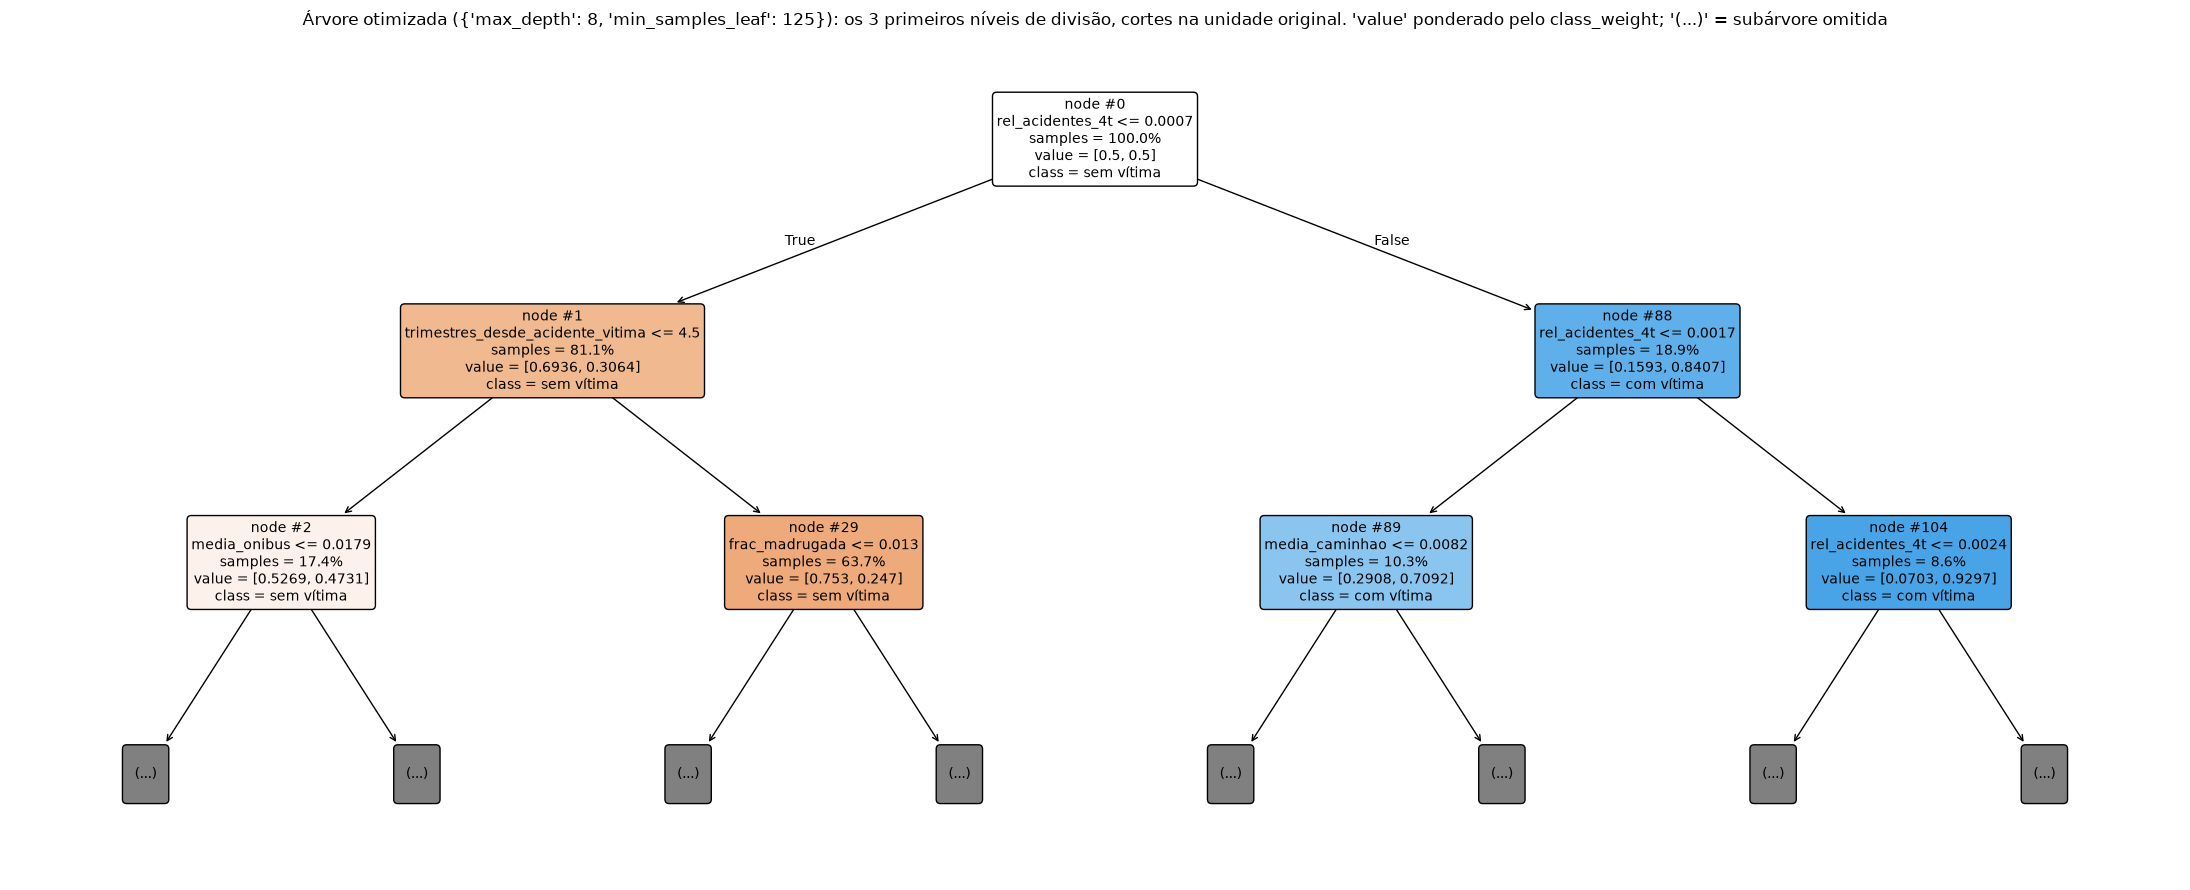

,nível,divisão,linhas treino,taxa real treino,linhas validação,taxa real validação
nó,,,,,,
0,0,rel_acidentes_4t ≤ 0.000673,13384,0.149,6692,0.208
1,1,trimestres_desde_acidente_vitima ≤ 4.5,10856,0.072,5476,0.116
2,2,media_onibus ≤ 0.0179,2325,0.135,1515,0.208
29,2,frac_madrugada ≤ 0.013,8531,0.054,3961,0.081
88,1,rel_acidentes_4t ≤ 0.00171,2528,0.479,1216,0.623
89,2,media_caminhao ≤ 0.0082,1383,0.299,703,0.448
104,2,rel_acidentes_4t ≤ 0.00245,1145,0.698,513,0.864


In [23]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(arv_leg, max_depth=2, feature_names=NOMES_ATR, class_names=["sem vítima", "com vítima"], filled=True,
          impurity=False, proportion=True, rounded=True, node_ids=True, precision=4, fontsize=10, ax=ax)
ax.set_title(f"Árvore otimizada ({params_melhor}): os 3 primeiros níveis de divisão, cortes na unidade original. "
             "'value' ponderado pelo class_weight; '(...)' = subárvore omitida", fontsize=12)
salvar(fig, "arvore_3_niveis.png")

t = arv_otim.tree_
profundidade_no = np.zeros(t.node_count, dtype=int)
for i in range(t.node_count):
    for filho in (t.children_left[i], t.children_right[i]):
        if filho != -1:
            profundidade_no[filho] = profundidade_no[i] + 1
nos = [i for i in range(t.node_count) if profundidade_no[i] <= 2]
pd.DataFrame({"nó": nos, "nível": profundidade_no[nos],
              "divisão": [f"{NOMES_ATR[t.feature[i]]} ≤ {arv_leg.tree_.threshold[i]:.3g}" if t.feature[i] >= 0 else "(folha)"
                          for i in nos],
              "linhas treino": n_tr[nos], "taxa real treino": pos_tr[nos] / n_tr[nos],
              "linhas validação": n_v[nos], "taxa real validação": pos_v[nos] / np.maximum(n_v[nos], 1)}).set_index("nó").round(3)

In [24]:
print(export_text(arv_leg, feature_names=NOMES_ATR, max_depth=3, decimals=4, show_weights=False))

|--- rel_acidentes_4t <= 0.0007
|   |--- trimestres_desde_acidente_vitima <= 4.5000
|   |   |--- media_onibus <= 0.0179
|   |   |   |--- frac_tarde <= 0.5635
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- frac_tarde >  0.5635
|   |   |   |   |--- class: 0
|   |   |--- media_onibus >  0.0179
|   |   |   |--- frac_noite <= 0.0408
|   |   |   |   |--- class: 0
|   |   |   |--- frac_noite >  0.0408
|   |   |   |   |--- truncated branch of depth 5
|   |--- trimestres_desde_acidente_vitima >  4.5000
|   |   |--- frac_madrugada <= 0.0130
|   |   |   |--- media_caminhao <= 0.1637
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- media_caminhao >  0.1637
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- frac_madrugada >  0.0130
|   |   |   |--- frac_madrugada <= 0.1644
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- frac_madrugada >  0.1644
|   |   |   |   |--- truncated branch of depth 4
|--- rel_acidentes_4t >  0.0007
|   |--- r

In [25]:
def caminhos_das_folhas(arv, nomes):
    t = arv.tree_
    caminhos = {}

    def descer(no, conds):
        if t.children_left[no] == -1:
            caminhos[no] = conds
            return
        f, c = nomes[t.feature[no]], t.threshold[no]
        descer(t.children_left[no], conds + [(f, "<=", c)])
        descer(t.children_right[no], conds + [(f, ">", c)])

    descer(0, [])
    return caminhos


def simplificar(conds):
    """Junta as condições da mesma coluna numa faixa só e escreve o one-hot como 'é' / 'não é'."""
    lim = {}
    for f, op, c in conds:
        lo, hi = lim.get(f, (-np.inf, np.inf))
        lim[f] = (max(lo, c), hi) if op == ">" else (lo, min(hi, c))
    partes_regra = []
    for f, (lo, hi) in lim.items():
        if " = " in f:
            partes_regra.append(f if lo > -np.inf else f"NÃO {f}")
        elif lo > -np.inf and hi < np.inf:
            partes_regra.append(f"{lo:.3g} < {f} ≤ {hi:.3g}")
        elif lo > -np.inf:
            partes_regra.append(f"{f} > {lo:.3g}")
        else:
            partes_regra.append(f"{f} ≤ {hi:.3g}")
    return " E ".join(partes_regra)


caminhos = caminhos_das_folhas(arv_leg, NOMES_ATR)
score_folha = arv_otim.tree_.value[:, 0, 1] / arv_otim.tree_.value[:, 0, :].sum(axis=1)
folhas = pd.DataFrame({
    "folha": list(caminhos),
    "score (ponderado)": [score_folha[f] for f in caminhos],
    "linhas treino": [n_tr[f] for f in caminhos],
    "taxa real treino": [pos_tr[f] / n_tr[f] for f in caminhos],
    "linhas validação": [n_v[f] for f in caminhos],
    "taxa real validação": [pos_v[f] / n_v[f] if n_v[f] else np.nan for f in caminhos],
    "regra": [simplificar(c) for c in caminhos.values()],
}).set_index("folha").sort_values("score (ponderado)", ascending=False)
folha_tr = arv_otim.apply(Ztr)
for col in ["acidentes_4t", "acidentes_vitima_4t"]:
    folhas[f"mediana {col} (treino)"] = partes["treino"][col].groupby(folha_tr).median().reindex(folhas.index)
folhas["linhas validação acumuladas"] = folhas["linhas validação"].cumsum()
folhas["positivos validação acumulados"] = (folhas["linhas validação"] * folhas["taxa real validação"].fillna(0)).cumsum()
print(f"{len(folhas)} folhas | as 5 de maior score cobrem {folhas['linhas validação'].head(5).sum()} linhas da validação "
      f"({folhas['linhas validação'].head(5).sum() / len(Xv):.1%}), com taxa real de "
      f"{folhas['positivos validação acumulados'].iloc[4] / folhas['linhas validação acumuladas'].iloc[4]:.3f} "
      f"(prevalência {yv.mean():.3f})")
usadas = sorted({ORIGEM[j] for j in arv_otim.tree_.feature if j >= 0})
print("colunas numéricas usadas e a mediana que substitui os nulos:",
      {c: round(float(mediana[c]), 3) for c in usadas if c in mediana.index})
print("nulos no treino nessas colunas:", {c: int(Xtr[c].isna().sum()) for c in usadas if c in mediana.index})
folhas.head(8).round(3)

59 folhas | as 5 de maior score cobrem 427 linhas da validação (6.4%), com taxa real de 0.899 (prevalência 0.208)
colunas numéricas usadas e a mediana que substitui os nulos: {'acidentes_2t': 0.0, 'acidentes_4t': 0.0, 'acidentes_bairro_1t': 9.0, 'frac_fim_de_semana': 0.188, 'frac_madrugada': 0.0, 'frac_manha': 0.333, 'frac_noite': 0.2, 'frac_tarde': 0.399, 'media_auto': 1.404, 'media_caminhao': 0.056, 'media_ciclista': 0.0, 'media_ciclom': 0.0, 'media_moto': 0.267, 'media_onibus': 0.059, 'media_pedestre': 0.0, 'rel_acidentes_2t': 0.0, 'rel_acidentes_4t': 0.0, 'trimestres_desde_acidente_vitima': 5.0}
nulos no treino nessas colunas: {'acidentes_2t': 0, 'acidentes_4t': 0, 'acidentes_bairro_1t': 0, 'frac_fim_de_semana': 17, 'frac_madrugada': 21, 'frac_manha': 21, 'frac_noite': 21, 'frac_tarde': 21, 'media_auto': 17, 'media_caminhao': 17, 'media_ciclista': 17, 'media_ciclom': 17, 'media_moto': 17, 'media_onibus': 17, 'media_pedestre': 17, 'rel_acidentes_2t': 0, 'rel_acidentes_4t': 0, 'trime

,score (ponderado),linhas treino,taxa real treino,linhas validação,taxa real validação,regra,mediana acidentes_4t (treino),mediana acidentes_vitima_4t (treino),linhas validação acumuladas,positivos validação acumulados
folha,,,,,,,,,,
116,0.996,138,0.978,133,0.970,rel_acidentes_4t > 0.00245 E acidentes_4t > 9.5 E acidentes_2t > 8.5,23.0,19.5,133,129.0
115,0.970,178,0.848,126,0.944,rel_acidentes_4t > 0.00245 E acidentes_4t > 9.5 E acidentes_2t ≤ 8.5,12.0,10.0,259,248.0
113,0.951,241,0.772,68,0.824,rel_acidentes_4t > 0.00245 E acidentes_4t ≤ 9.5 E frac_fim_de_semana > 0.183,7.0,6.0,327,304.0
112,0.916,180,0.656,52,0.808,rel_acidentes_4t > 0.00245 E acidentes_4t ≤ 9.5 E frac_fim_de_semana ≤ 0.183,7.0,5.0,379,346.0
107,0.901,153,0.614,48,0.792,0.00171 < rel_acidentes_4t ≤ 0.00245 E media_ciclista ≤ 0.0292 E acidentes_bairro_1t ≤ 14.5,4.0,4.0,427,384.0
102,0.891,141,0.589,102,0.608,0.000673 < rel_acidentes_4t ≤ 0.00171 E media_caminhao > 0.0082 E frac_madrugada > 0.0112 E 0.00183 < media_ciclom ≤ 0.018,3.0,2.0,529,446.0
108,0.843,130,0.485,51,0.706,0.00171 < rel_acidentes_4t ≤ 0.00245 E media_ciclista ≤ 0.0292 E acidentes_bairro_1t > 14.5,4.0,4.0,580,482.0
109,0.803,125,0.416,35,0.657,0.00171 < rel_acidentes_4t ≤ 0.00245 E media_ciclista > 0.0292,4.0,4.0,615,505.0


In [26]:
print("As 8 folhas de menor score:")
display(folhas.tail(8).round(3))
print("Correlação de Spearman entre a taxa real da folha no treino e na validação (folhas com ≥ 30 linhas na validação):",
      round(folhas.loc[folhas["linhas validação"] >= 30, ["taxa real treino", "taxa real validação"]]
            .corr(method="spearman").iloc[0, 1], 3))

As 8 folhas de menor score:


,score (ponderado),linhas treino,taxa real treino,linhas validação,taxa real validação,regra,mediana acidentes_4t (treino),mediana acidentes_vitima_4t (treino),linhas validação acumuladas,positivos validação acumulados
folha,,,,,,,,,,
57,0.109,286,0.021,123,0.081,rel_acidentes_4t ≤ 0.000673 E trimestres_desde_acidente_vitima > 4.5 E frac_madrugada ≤ 0.013 E media_caminhao > 0.164 E frac_fim_de_semana ≤ 0.431 E NÃO situacao_placa = NAO HA PLACAS E frac_tard...,0.0,0.0,5935,1350.0
38,0.096,164,0.018,80,0.025,rel_acidentes_4t ≤ 0.000673 E trimestres_desde_acidente_vitima > 4.5 E frac_madrugada ≤ 0.013 E media_caminhao ≤ 0.0389 E NÃO divisao_via1 = FAIXA CONTINUA E acidente_verificado = CRUZAMENTO E med...,0.0,0.0,6015,1352.0
84,0.091,174,0.017,101,0.089,rel_acidentes_4t ≤ 0.000673 E trimestres_desde_acidente_vitima > 10.5 E frac_madrugada > 0.164 E NÃO situacao_placa = NAO HA PLACAS,0.0,0.0,6116,1361.0
60,0.063,173,0.012,85,0.047,rel_acidentes_4t ≤ 0.000673 E trimestres_desde_acidente_vitima > 4.5 E frac_madrugada ≤ 0.013 E media_caminhao > 0.164 E frac_fim_de_semana ≤ 0.431 E NÃO situacao_placa = NAO HA PLACAS E frac_tard...,0.0,0.0,6201,1365.0
64,0.042,261,0.008,118,0.042,rel_acidentes_4t ≤ 0.000673 E 4.5 < trimestres_desde_acidente_vitima ≤ 6.5 E frac_madrugada ≤ 0.013 E media_caminhao > 0.164 E 0.157 < frac_fim_de_semana ≤ 0.431 E situacao_placa = NAO HA PLACAS,0.0,0.0,6319,1370.0
56,0.023,496,0.004,254,0.043,rel_acidentes_4t ≤ 0.000673 E trimestres_desde_acidente_vitima > 4.5 E frac_madrugada ≤ 0.013 E media_caminhao > 0.164 E frac_fim_de_semana ≤ 0.431 E NÃO situacao_placa = NAO HA PLACAS E frac_tard...,0.0,0.0,6573,1381.0
83,0.000,126,0.000,48,0.083,rel_acidentes_4t ≤ 0.000673 E 4.5 < trimestres_desde_acidente_vitima ≤ 10.5 E frac_madrugada > 0.164 E NÃO situacao_placa = NAO HA PLACAS E frac_fim_de_semana > 0.321,0.0,0.0,6621,1385.0
82,0.000,127,0.000,71,0.099,rel_acidentes_4t ≤ 0.000673 E 4.5 < trimestres_desde_acidente_vitima ≤ 10.5 E frac_madrugada > 0.164 E NÃO situacao_placa = NAO HA PLACAS E frac_fim_de_semana ≤ 0.321,0.0,0.0,6692,1392.0


Correlação de Spearman entre a taxa real da folha no treino e na validação (folhas com ≥ 30 linhas na validação): 0.873


**Leitura: a árvore é, antes de tudo, uma régua de recorrência.**

*Como ler os cortes de `rel_acidentes_4t`.* `rel_acidentes_4t` é a fração dos acidentes da cidade nos
últimos 4 trimestres que caiu no local. Para a mesma fração, o número de acidentes cresce com o total
da cidade, que foi de 1.964 (2021Q1) a 3.575 (2023Q4). Pela tabela de equivalência, os três cortes da
árvore correspondem a:

- **0,000673:** de 1,3 a 1,6 acidentes nos 4 trimestres em 2021–2022 (ou seja, **2 ou mais**) e de 1,7
  a 2,4 em 2023;
- **0,00171:** de 3,4 a 4,1 em 2021–2022 (**4 ou mais**) e de 4,3 a 6,1 em 2023;
- **0,00245:** de 4,8 a 5,9 em 2021–2022 (**5 a 6 ou mais**) e de 6,2 a 8,7 em 2023.

*Nulos.* `trimestres_desde_acidente_vitima` é nulo em 3.261 linhas do treino (locais que nunca tiveram
acidente com vítima) e entra na árvore com a mediana, 5. Assim, "> 4,5" quer dizer "há mais de 4
trimestres **ou nunca**".

**Os 3 primeiros níveis.** A raiz corta em `rel_acidentes_4t ≤ 0,000673`, que equivale a **até 1
acidente no último ano**. Esse lado tem 81,1% das linhas do treino (10.856), com taxa real de 0,072 no
treino e 0,116 em 2023. O outro lado tem 2.528 linhas, com taxa de 0,479 e 0,623. Do lado sem
histórico, a árvore separa quem teve acidente com vítima nos últimos 4 trimestres (taxa de 0,135 e
0,208) de quem não teve ou nunca teve (0,054 e 0,081). Do lado com histórico, ela volta a cortar na
mesma coluna: com cerca de 4 acidentes ou mais no ano (nó 104), a taxa sobe para 0,698 no treino e
0,864 em 2023.

**As regras das folhas de maior risco, em linguagem simples** (taxa real de acidente com vítima no
trimestre seguinte, no treino 2021–2022 → na validação 2023):

1. **Folha 116.** Local com **10 ou mais acidentes no último ano e 9 ou mais só no último semestre**:
   0,978 → 0,970 (138 e 133 linhas; mediana de 23 acidentes, 19,5 com vítima). É praticamente certo
   que haverá acidente com vítima no trimestre seguinte.
2. **Folha 115.** Local com **10 ou mais acidentes no último ano**, mas menos de 9 no último semestre:
   0,848 → 0,944 (178 e 126 linhas; mediana de 12 acidentes).
3. **Folhas 113 e 112.** Local acima do corte de 0,00245 (5 a 6 acidentes ou mais no ano, em
   2021–2022) e **com até 9 acidentes no ano**: 0,772 → 0,824 quando mais de 18% dos acidentes do
   local caem no fim de semana (folha 113), e 0,656 → 0,808 quando não (folha 112). A mediana é de 7
   acidentes nas duas.
4. **Folha 107.** Local entre os cortes 0,00171 e 0,00245 (**cerca de 4 a 5 acidentes no ano**), sem
   ciclista envolvido no histórico (`media_ciclista ≤ 0,029`) e num bairro com **até 14 acidentes no
   último trimestre**: 0,614 → 0,792 (mediana de 4 acidentes, 4 com vítima).
5. **Folha 102.** Local com **cerca de 2 a 3 acidentes no ano**, com caminhão e madrugada no histórico
   e uma faixa estreita de `media_ciclom`: 0,589 → 0,608. Essa regra combina quatro condições de
   perfil e é a menos estável para uso operacional.

Juntas, as 5 folhas de maior score cobrem 427 linhas da validação (6,4%), com taxa real de 0,899,
contra uma prevalência de 0,208. **As regras valem em 2023.** A taxa de cada folha no treino e em 2023
tem Spearman de 0,873, e 7 das 8 folhas de maior score têm taxa *maior* em 2023, junto com a
prevalência (a exceção é a folha 116, com 0,978 → 0,970). No outro extremo, as folhas de menor score juntam locais sem histórico (mediana de 0
acidentes). Elas têm taxa de 0,000 a 0,021 no treino e de 0,025 a 0,099 em 2023. As folhas 82 e 83,
com score 0, têm 0,099 e 0,083 em 2023: o "risco zero" do treino não se confirma no ano seguinte.

### Importância por impureza × importância por permutação

- **Impureza** (`feature_importances_`): a redução total do Gini (ponderado) que cada coluna
  proporciona nas divisões, medida **no treino**. Somo as colunas do one-hot de volta na coluna
  original para comparar com a permutação.
- **Permutação** (`metricas.importancia_permutacao`): a queda média de PR-AUC **na validação de
  2023** ao embaralhar cada coluna original (5 repetições, semente 42), com a árvore ajustada no
  treino.

tempo da permutação: 6.8 s (48 colunas × 5 repetições)


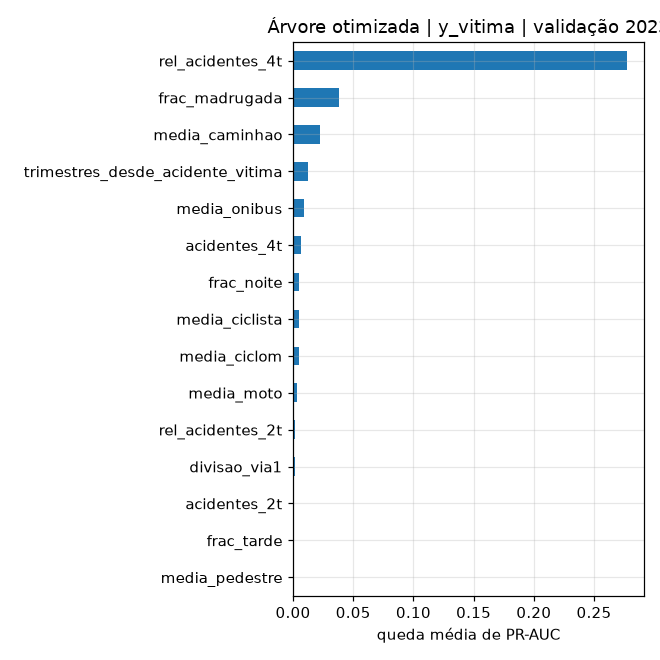

colunas com impureza > 0: 24 de 48 | com queda de permutação > 0: 23 | < 0: 1
Spearman impureza × permutação (colunas usadas pela árvore): 0.607


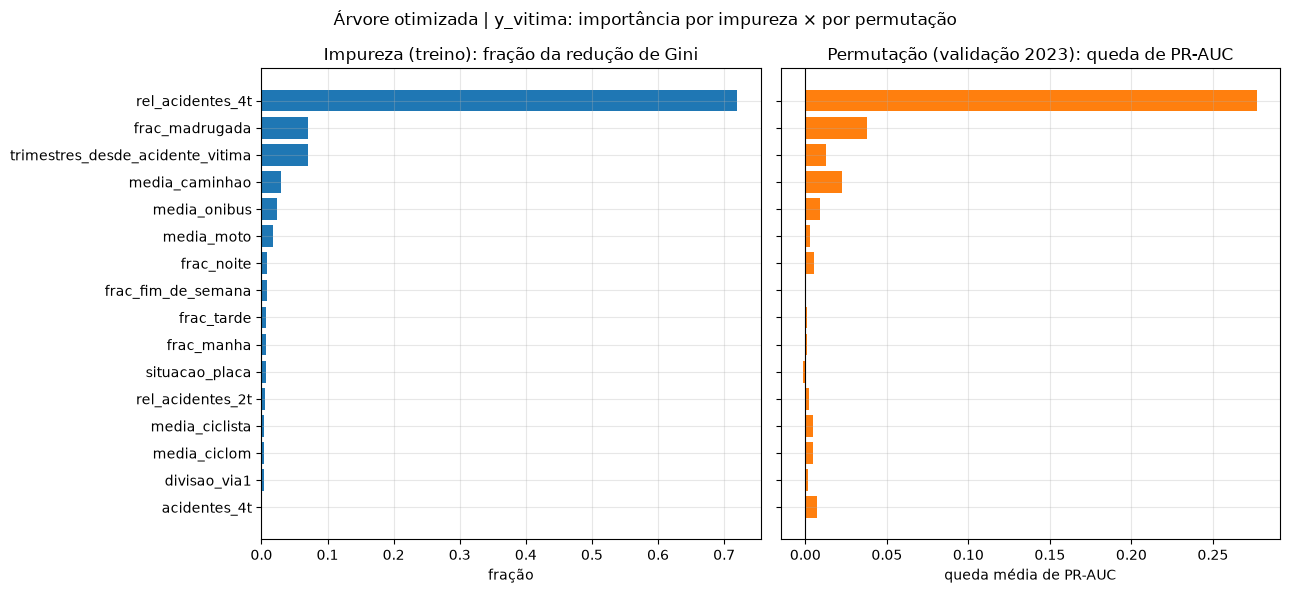

,impureza (fração),permutação (queda de PR-AUC),posição impureza,posição permutação,permutação ÷ soma das positivas
rel_acidentes_4t,7.194e-01,2.772e-01,1,1,0.704
frac_madrugada,7.060e-02,3.810e-02,2,2,0.097
trimestres_desde_acidente_vitima,7.040e-02,1.280e-02,3,4,0.033
media_caminhao,2.930e-02,2.220e-02,4,3,0.056
media_onibus,2.390e-02,8.900e-03,5,5,0.022
media_moto,1.750e-02,2.900e-03,6,10,0.007
frac_noite,8.300e-03,5.200e-03,7,7,0.013
frac_fim_de_semana,7.700e-03,6.000e-04,8,19,0.002
frac_tarde,7.100e-03,1.000e-03,9,14,0.003
frac_manha,6.900e-03,9.000e-04,10,16,0.002


In [27]:
imp_impureza = pd.Series(arv_otim.feature_importances_, index=ORIGEM).groupby(level=0).sum().sort_values(ascending=False)
t0 = time.time()
_, imp_perm = metricas.importancia_permutacao(pipe_otim, Xv, yv, FIG / "permutation_importance.png",
                                              f"{titulo_otim} | validação 2023", top=15)
print(f"tempo da permutação: {time.time() - t0:.1f} s ({Xv.shape[1]} colunas × 5 repetições)")
display(Image(FIG / "permutation_importance.png"))
imp = pd.DataFrame({"impureza (fração)": imp_impureza, "permutação (queda de PR-AUC)": imp_perm}).fillna(0)
imp["posição impureza"] = imp["impureza (fração)"].rank(ascending=False, method="min").astype(int)
imp["posição permutação"] = imp["permutação (queda de PR-AUC)"].rank(ascending=False, method="min").astype(int)
imp["permutação ÷ soma das positivas"] = imp["permutação (queda de PR-AUC)"] / imp["permutação (queda de PR-AUC)"].clip(lower=0).sum()
imp = imp.sort_values("impureza (fração)", ascending=False)
print(f"colunas com impureza > 0: {(imp['impureza (fração)'] > 0).sum()} de {len(imp)} | "
      f"com queda de permutação > 0: {(imp['permutação (queda de PR-AUC)'] > 0).sum()} | "
      f"< 0: {(imp['permutação (queda de PR-AUC)'] < 0).sum()}")
print("Spearman impureza × permutação (colunas usadas pela árvore):",
      round(imp.loc[imp["impureza (fração)"] > 0, ["impureza (fração)", "permutação (queda de PR-AUC)"]]
            .corr(method="spearman").iloc[0, 1], 3))

top = imp[(imp["posição impureza"] <= 12) | (imp["posição permutação"] <= 12)]
fig, axs = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
ordem_top = top.sort_values("impureza (fração)").index
axs[0].barh(ordem_top, top.loc[ordem_top, "impureza (fração)"], color="C0")
axs[0].set(title="Impureza (treino): fração da redução de Gini", xlabel="fração")
axs[1].barh(ordem_top, top.loc[ordem_top, "permutação (queda de PR-AUC)"], color="C1")
axs[1].axvline(0, color="k", lw=.8)
axs[1].set(title="Permutação (validação 2023): queda de PR-AUC", xlabel="queda média de PR-AUC")
fig.suptitle(f"{titulo_otim}: importância por impureza × por permutação")
salvar(fig, "importancia_impureza_x_permutacao.png")
top.round(4)

**Leitura: as duas medidas concordam no essencial e divergem nos detalhes.**

- **O essencial é o mesmo.** `rel_acidentes_4t` responde por **72%** da redução de impureza e por
  **70%** da queda de PR-AUC na permutação (0,277). Depois vêm `frac_madrugada` (0,071 e 0,038),
  `trimestres_desde_acidente_vitima`, `media_caminhao` e `media_onibus`, nas posições 2 a 5 das duas
  medidas, com ordem um pouco diferente. A árvore usa 24 das 48 colunas originais. Na permutação, 23
  têm queda positiva e 1 tem queda negativa. O Spearman entre as duas medidas, nas colunas usadas, é
  0,607.
- **`acidentes_4t` é a maior diferença:** 21ª posição na impureza (0,0008) e 6ª na permutação (0,0069).
  A impureza pesa cada divisão pelo nº de linhas que passam pelo nó. `acidentes_4t` só divide o topo
  da árvore (o corte de 9,5 que separa as folhas 115 e 116 das folhas 112 e 113), com poucas linhas.
  Mas é justamente aí que fica o começo da lista, que pesa no PR-AUC.
- **`situacao_placa` vai na direção contrária:** 11ª na impureza (0,0067), mas com queda *negativa* na
  permutação (−0,0012). A divisão ajuda a separar folhas de risco baixo no treino, e embaralhar a
  coluna melhora um pouco o PR-AUC de 2023. É ruído aprendido no treino.
- **Os perfis horários** (`frac_fim_de_semana`, `frac_tarde`, `frac_manha`) ficam nas posições 8 a 10
  da impureza e caem para 14 a 19 na permutação. São divisões fundas, na região de risco baixo, que
  reduzem a impureza mas quase não mudam a ordem do topo.
- **De onde vêm as diferenças:** a impureza é medida no treino, com o peso do `class_weight`, e premia
  qualquer divisão que limpe um nó grande. A permutação é medida em 2023, sobre o PR-AUC, e só premia
  o que muda a ordem dos locais. Para explicar o modelo à CTTU, vale a permutação.

## 10. Erros na validação de 2023, no limiar escolhido

O limiar é o que maximiza o F1 na validação (`metricas.escolher_limiar`, como no `_rodar`). Acima
dele, o local é apontado como de risco. Falsos positivos: apontados, sem acidente com vítima no
trimestre seguinte. Falsos negativos: não apontados, com acidente. Os nomes vêm de `dim_local`.
`trimestre` é o da linha (das features) e `trimestre_alvo` é o seguinte, em que o acidente
aconteceu ou não. Como o score só tem um valor por folha, a coluna `folha` mostra de onde vem cada
erro, e os "maiores" erros de cada lado são empates: a tabela mostra os primeiros na ordem estável.

In [28]:
from src.comum.db import engine

dim = pd.read_sql_table("dim_local", engine())[["local_id", "bairro", "logradouro"]]
erros = (partes["validacao"][["local_id", "trimestre", "acidentes_vitima_4t", "acidentes_4t", ALVO]]
         .assign(score=score_otim, folha=folha_v).merge(dim, on="local_id", how="left"))
erros["trimestre_alvo"] = (pd.PeriodIndex(erros["trimestre"], freq="Q") + 1).astype(str)
limiar = m_otim["limiar"]
erros["apontado"] = erros["score"] >= limiar
colunas = ["bairro", "logradouro", "trimestre", "trimestre_alvo", "folha", "score", "acidentes_vitima_4t", "acidentes_4t"]
fp = erros[(erros[ALVO] == 0) & erros["apontado"]].sort_values("score", ascending=False, kind="stable")
fn = erros[(erros[ALVO] == 1) & ~erros["apontado"]].sort_values("score", kind="stable")
vp = erros[(erros[ALVO] == 1) & erros["apontado"]]
print(f"limiar (F1 na validação): {limiar:.4f} | apontados: {int(erros['apontado'].sum())} de {len(erros)} | "
      f"VP {len(vp)} | FP {len(fp)} (métricas: {int(m_otim['fp'])}) | FN {len(fn)} (métricas: {int(m_otim['fn'])})")
print(f"folhas acima do limiar: {erros.loc[erros['apontado'], 'folha'].nunique()} de {arv_otim.get_n_leaves()}")
print(f"negativos empatados no maior score: {(fp['score'] == fp['score'].iloc[0]).sum()} | "
      f"positivos empatados no menor score: {(fn['score'] == fn['score'].iloc[0]).sum()}")
print("\n10 maiores falsos positivos")
display(fp[colunas].head(10).reset_index(drop=True))
print("10 maiores falsos negativos (menor score)")
display(fn[colunas].head(10).reset_index(drop=True))

limiar (F1 na validação): 0.6181 | apontados: 1480 de 6692 | VP 856 | FP 624 (métricas: 624) | FN 536 (métricas: 536)
folhas acima do limiar: 16 de 59
negativos empatados no maior score: 4 | positivos empatados no menor score: 11

10 maiores falsos positivos


,bairro,logradouro,trimestre,trimestre_alvo,folha,score,acidentes_vitima_4t,acidentes_4t
0,SÃO JOSÉ,RUA IMPERIAL,2023Q1,2023Q2,116,0.996,12,17
1,CAMPO GRANDE,RUA ODORICO MENDES,2023Q3,2023Q4,116,0.996,16,16
2,ARRUDA,RUA DAS MOCAS,2023Q4,2024Q1,116,0.996,7,10
3,DOIS IRMÃOS,RUA MANUEL DE MEDEIROS,2023Q4,2024Q1,116,0.996,18,18
4,BOA VISTA,AV GOVERNADOR AGAMENON MAGALHAES,2023Q1,2023Q2,115,0.970,10,15
5,BOA VIAGEM,RUA RIBEIRO DE BRITO,2023Q1,2023Q2,115,0.970,10,12
6,ENCRUZILHADA,AV NORTE MIGUEL ARRAES DE ALENCAR,2023Q1,2023Q2,115,0.970,10,10
7,TEJIPIÓ,AV DR JOSE RUFINO,2023Q2,2023Q3,115,0.970,12,14
8,DOIS UNIDOS,AV HILDEBRANDO DE VASCONCELOS,2023Q3,2023Q4,115,0.970,8,10
9,GRAÇAS,AV RUI BARBOSA,2023Q4,2024Q1,115,0.970,7,10


10 maiores falsos negativos (menor score)


,bairro,logradouro,trimestre,trimestre_alvo,folha,score,acidentes_vitima_4t,acidentes_4t
0,ESPINHEIRO,RUA BUENOS AYRES,2023Q1,2023Q2,82,0.0,0,1
1,PARNAMIRIM,AV RUI BARBOSA,2023Q1,2023Q2,83,0.0,0,0
2,BREJO DE BEBERIBE,AV VEREADOR OTACILIO AZEVEDO,2023Q2,2023Q3,82,0.0,0,0
3,BOA VIAGEM,RUA ATLANTICO,2023Q2,2023Q3,83,0.0,0,0
4,BOA VIAGEM,RUA GENERAL AMERICANO FREIRE,2023Q2,2023Q3,83,0.0,0,0
5,AFOGADOS,RUA SANTA EDWIRGES,2023Q2,2023Q3,82,0.0,0,0
6,VÁRZEA,AV BARAO DE BONITO,2023Q3,2023Q4,83,0.0,0,0
7,VÁRZEA,RUA FRANCISCO LACERDA,2023Q3,2023Q4,82,0.0,0,0
8,SÃO JOSÉ,RUA DR JOSE MARIANO,2023Q3,2023Q4,82,0.0,0,0
9,CASA AMARELA,RUA ALEXANDRINO,2023Q4,2024Q1,82,0.0,0,0


In [29]:
sem_hist_fn = int((fn["acidentes_4t"] == 0).sum())
sem_vit_fn = int((fn["acidentes_vitima_4t"] == 0).sum())
print(f"falsos negativos sem nenhum acidente nos 4 trimestres anteriores (acidentes_4t == 0): {sem_hist_fn} de {len(fn)} "
      f"({sem_hist_fn / len(fn):.1%})")
print(f"falsos negativos sem acidente com vítima nos 4 trimestres anteriores (acidentes_vitima_4t == 0): {sem_vit_fn} "
      f"de {len(fn)} ({sem_vit_fn / len(fn):.1%})")
pos_sem_hist = erros[(erros[ALVO] == 1) & (erros["acidentes_4t"] == 0)]
print(f"todos os positivos sem histórico (acidentes_4t == 0): {len(pos_sem_hist)} de {int(erros[ALVO].sum())}; "
      f"apontados pela árvore: {int(pos_sem_hist['apontado'].sum())}")
resumo_erros = pd.DataFrame({
    grupo: {"linhas": len(g), "acidentes_vitima_4t (média)": g["acidentes_vitima_4t"].mean(),
            "acidentes_vitima_4t (mediana)": g["acidentes_vitima_4t"].median(),
            "acidentes_4t == 0": int((g["acidentes_4t"] == 0).sum()), "locais distintos": g["local_id"].nunique()}
    for grupo, g in [("verdadeiros positivos", vp), ("falsos positivos", fp), ("falsos negativos", fn),
                     ("verdadeiros negativos", erros[(erros[ALVO] == 0) & ~erros["apontado"]])]}).T
display(resumo_erros.round(2))
print("locais com mais falsos positivos (trimestres de 2023 em que foram apontados e não tiveram acidente com vítima):")
display(fp.groupby(["bairro", "logradouro"]).size().sort_values(ascending=False).head(8).to_frame("trimestres FP"))

falsos negativos sem nenhum acidente nos 4 trimestres anteriores (acidentes_4t == 0): 302 de 536 (56.3%)
falsos negativos sem acidente com vítima nos 4 trimestres anteriores (acidentes_vitima_4t == 0): 345 de 536 (64.4%)
todos os positivos sem histórico (acidentes_4t == 0): 315 de 1392; apontados pela árvore: 13


,linhas,acidentes_vitima_4t (média),acidentes_vitima_4t (mediana),acidentes_4t == 0,locais distintos
verdadeiros positivos,856.0,7.54,5.0,13.0,357.0
falsos positivos,624.0,2.33,2.0,30.0,335.0
falsos negativos,536.0,0.51,0.0,302.0,437.0
verdadeiros negativos,4676.0,0.23,0.0,3553.0,1339.0


locais com mais falsos positivos (trimestres de 2023 em que foram apontados e não tiveram acidente com vítima):


,,trimestres FP
bairro,logradouro,
IBURA,AV CHAPADA DO ARARIPE,4
BEBERIBE,PRC DA CONVENCAO,4
FUNDÃO,RUA DO MACHADO,4
IBURA,RUA DR OTAVIO DE MORAES VASCONCELOS,4
CURADO,AV PREFEITO ANTONIO PEREIRA,4
CORDEIRO,RUA HONORIO CORREIA,4
IMBIRIBEIRA,RUA IZABEL DE SOUZA,4
IPUTINGA,RUA EMILIANO BRAGA,4


**Leitura.**

- **No limiar escolhido (0,618)**, a árvore aponta 1.480 das 6.692 linhas (16 das 59 folhas ficam
  acima dele): 856 verdadeiros positivos, 624 falsos positivos e 536 falsos negativos.
- **Falsos positivos.** Os maiores são locais com histórico muito alto que, naquele trimestre, não
  tiveram acidente com vítima. Quatro empatam no maior score (0,996, folha 116): a Rua Imperial (São
  José, 12 acidentes com vítima de 17 nos 4 trimestres anteriores), a Rua Odorico Mendes (Campo
  Grande, 16 de 16), a Rua das Moças (Arruda, 7 de 10) e a Rua Manuel de Medeiros (Dois Irmãos, 18 de
  18). Logo depois vêm vias da folha 115, como a Av. Governador Agamenon Magalhães (Boa Vista), a Av.
  Norte Miguel Arraes de Alencar (Encruzilhada) e a Av. Rui Barbosa (Graças). No conjunto, porém, os
  falsos positivos têm histórico moderado: média de 2,33 acidentes com vítima nos 4 trimestres
  anteriores (mediana de 2), contra 7,54 (mediana de 5) dos verdadeiros positivos. Pelo menos oito locais
  foram falsos positivos nos 4 trimestres de 2023, como a Av. Chapada do Araripe (Ibura), a Praça da
  Convenção (Beberibe) e a Rua do Machado (Fundão).
- **Falsos negativos.** Onze positivos empatam no menor score (0, folhas 82 e 83). Entre os 10
  mostrados, nove não têm nenhum acidente nos 4 trimestres anteriores, e um (Rua Buenos Ayres, no
  Espinheiro) tem 1 acidente sem vítima. **Dos 536 falsos negativos, 302 (56,3%) vêm de locais sem
  nenhum acidente nos 4 trimestres anteriores**, e 345 (64,4%) de locais sem acidente com vítima nesse
  período. Na validação inteira há 315 positivos sem histórico, e a árvore aponta 13 deles.
- O erro dominante é o mesmo da heurística e dos outros modelos: o primeiro acidente de um local
  "quieto" não é previsível com estas features. Os falsos negativos estão espalhados por 437 locais
  distintos.

## 11. Custo: tempo de ajuste e de predição

Mediana de 3 repetições, ajuste no treino inteiro e predição na validação, com o pipeline inteiro
(pré-processamento incluído). O Random Forest padrão entra só como referência.

In [30]:
def cronometrar(pipe, Xa, ya, Xp, rep=3):
    tf, tp = [], []
    for _ in range(rep):
        p = clone(pipe)
        t0 = time.perf_counter(); p.fit(Xa, ya); tf.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); p.predict_proba(Xp); tp.append(time.perf_counter() - t0)
    return float(np.median(tf)), float(np.median(tp))


custo = {}
for nome, pipe in [(NOMES["regressao_logistica"], montar_pipeline(features, "regressao_logistica")),
                   (NOMES["arvore_padrao"], montar_pipeline(features, MODELO)),
                   (NOMES["arvore_otimizada"], pipe_otim),
                   (NOMES["random_forest_referencia"], montar_pipeline(features, "random_forest"))]:
    tf, tp = cronometrar(pipe, Xtr, ytr, Xv)
    custo[nome] = {"ajuste (s)": tf, "predição na validação (s)": tp}
custo = pd.DataFrame(custo).T
custo["ajuste ÷ Regressão Logística"] = custo["ajuste (s)"] / custo.loc[NOMES["regressao_logistica"], "ajuste (s)"]
custo["predição ÷ Regressão Logística"] = (custo["predição na validação (s)"]
                                            / custo.loc[NOMES["regressao_logistica"], "predição na validação (s)"])
print(f"{len(Xtr)} linhas de treino | {len(Xv)} linhas de validação | busca Optuna de 40 trials: {tempo_busca:.1f} s")
custo.round(3)

13384 linhas de treino | 6692 linhas de validação | busca Optuna de 40 trials: 27.4 s


,ajuste (s),predição na validação (s),ajuste ÷ Regressão Logística,predição ÷ Regressão Logística
Regressão Logística padrão,2.245,0.072,1.000,1.000
Árvore padrão,0.206,0.024,0.092,0.340
Árvore otimizada (Optuna 40),0.211,0.024,0.094,0.340
Random Forest padrão (referência),1.234,0.092,0.550,1.282


**Leitura.** A árvore é o modelo mais barato do grupo. O ajuste no treino inteiro leva 0,21 s,
0,094 vez o tempo da Regressão Logística (2,25 s), e a predição das 6.692 linhas leva 0,024 s
(0,34 vez o da Regressão Logística). O Random Forest de referência leva 1,23 s para ajustar e 0,092 s
para predizer. A busca de 40 trials levou 27,4 s. Com estes volumes, o custo não decide a escolha
entre nenhum dos modelos.

## 12. Alvo secundário: `y_atropelamento`

A melhor configuração de `y_vitima` (sem nova busca) reavaliada em `y_atropelamento`, com as
mesmas partes e os mesmos folds, ao lado dos pisos e da Árvore padrão. Só a otimizada vira run
(`busca=optuna_40`, alvo `y_atropelamento`).

**Ressalva (`ARCHITECTURE.md`, 17.2):** o atropelamento tem poucos positivos por trimestre. Com
tão poucos eventos, o PR-AUC oscila muito de um fold para outro, e as diferenças entre modelos têm
de ser lidas contra esse desvio. Aqui o teto do Recall@50 é 1, mas o teto da precisão@50 é baixo:
com menos de 50 positivos por trimestre, nem um ranking perfeito acerta 50.

In [31]:
ALVO2 = "y_atropelamento"
partes2, folds2 = preparar(ALVO2)
Xtr2, ytr2 = _xy(partes2["treino"], ALVO2)
Xv2, yv2 = _xy(partes2["validacao"], ALVO2)
tri2, tri_v2 = partes2["treino"]["trimestre"].to_numpy(), partes2["validacao"]["trimestre"]
print(f"positivos: treino {ytr2.sum()} ({ytr2.mean():.4f}) | validação {yv2.sum()} ({yv2.mean():.4f})")
print("positivos na validação de cada fold:", {tri2[te][0]: int(ytr2.iloc[te].sum()) for _, te in folds2})
pos2 = partes2["validacao"].groupby("trimestre")[ALVO2].sum()
print("positivos por trimestre na validação 2023:", pos2.astype(int).to_dict())
for k in metricas.KS:
    TETO[(ALVO2, k)] = teto_recall(yv2, tri_v2, k)
    print(f"k={k}: teto do Recall@k {TETO[(ALVO2, k)]:.3f} | teto da precisão@k {float((np.minimum(k, pos2) / k).mean()):.3f}")

for nome, r in pisos(ALVO2, partes2, folds2).items():
    resultados[(ALVO2, nome)] = r
resultados[(ALVO2, "arvore_padrao")] = avaliar_pipe(montar_pipeline(features, MODELO), ALVO2, partes2, folds2)

pipe_otim2 = montar_pipeline(features, MODELO, **params_melhor)
cv_otim2 = {**_cv(pipe_otim2, Xtr2, ytr2, folds2), **_cv_estratificado(pipe_otim2, Xtr2, ytr2)}
run_otim2, m_otim2 = _rodar(f"{MODELO}_optuna40_melhor", ALVO2, pipe_otim2, partes2, params_melhor, cv_otim2,
                            {"etapa": "otimizacao", "busca": "optuna_40", **TAGS}, folds2)
resultados[(ALVO2, "arvore_otimizada")] = linha(cv_otim2, m_otim2, run_otim2)
score_otim2 = pipe_otim2.predict_proba(Xv2)[:, 1]
print("run", run_otim2, "| folhas:", pipe_otim2.named_steps["modelo"].get_n_leaves(),
      "| scores distintos na validação:", scores_distintos(score_otim2))
folds2_df = pd.DataFrame({
    NOMES["heuristica_recorrencia"]: por_fold(score=score_heuristica(partes2["treino"]), X=Xtr2, y=ytr2, splits=folds2),
    NOMES["regressao_logistica"]: por_fold(montar_pipeline(features, "regressao_logistica"), X=Xtr2, y=ytr2, splits=folds2),
    NOMES["arvore_padrao"]: por_fold(montar_pipeline(features, MODELO), X=Xtr2, y=ytr2, splits=folds2),
    NOMES["arvore_otimizada"]: por_fold(pipe_otim2, X=Xtr2, y=ytr2, splits=folds2),
}, index=[tri2[te][0] for _, te in folds2])
print("\nPR-AUC por fold temporal (y_atropelamento):")
display(folds2_df.round(3))
print("Recall@50 da Árvore otimizada com os empates (y_atropelamento):",
      {k: round(v, 4) for k, v in recall_com_empates(yv2, score_otim2, tri_v2, 50).items()})
tabela(ALVO2, ["heuristica_recorrencia", "regressao_logistica", "arvore_padrao", "arvore_otimizada"])

positivos: treino 313 (0.0234) | validação 151 (0.0226)
positivos na validação de cada fold: {'2022Q1': 46, '2022Q2': 48, '2022Q3': 44, '2022Q4': 42}
positivos por trimestre na validação 2023: {'2023Q1': 40, '2023Q2': 40, '2023Q3': 36, '2023Q4': 35}
k=50: teto do Recall@k 1.000 | teto da precisão@k 0.755
k=100: teto do Recall@k 1.000 | teto da precisão@k 0.378


2026/11/24 12:53:44 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run arvore_decisao_optuna40_melhor at: http://mlflow:5000/#/experiments/2/runs/fdb65d7af4f449428460e083da949454
🧪 View experiment at: http://mlflow:5000/#/experiments/2
run fdb65d7af4f449428460e083da949454 | folhas: 37 | scores distintos na validação: 31



PR-AUC por fold temporal (y_atropelamento):


,Heurística de recorrência,Regressão Logística padrão,Árvore padrão,Árvore otimizada (Optuna 40)
2022Q1,0.341,0.292,0.128,0.240
2022Q2,0.296,0.302,0.236,0.219
2022Q3,0.316,0.286,0.267,0.195
2022Q4,0.318,0.332,0.207,0.164


Recall@50 da Árvore otimizada com os empates (y_atropelamento): {'Recall@50 (no_topo)': 0.3592, 'Recall@50 (pior caso)': 0.2636, 'Recall@50 (esperado)': 0.3285, 'Recall@50 (melhor caso)': 0.418, 'Precisão@50 (no_topo)': 0.27, 'linhas empatadas no corte do 50º (média por trimestre)': 22.0}


,CV temporal PR-AUC,CV temporal ROC-AUC,CV estratificado PR-AUC,Δ PR-AUC estrat. − temporal,Val PR-AUC,Val Recall@50,Val Recall@100,Val Precisão@50,Val Precisão@100,Val ROC-AUC
Heurística de recorrência,0.318 ± 0.016,0.841 ± 0.023,0.272 ± 0.050,-0.046,0.290,0.424,0.562,0.320,0.212,0.828
Regressão Logística padrão,0.303 ± 0.018,0.818 ± 0.013,0.274 ± 0.064,-0.029,0.278,0.418,0.558,0.315,0.210,0.823
Árvore padrão,0.210 ± 0.052,0.735 ± 0.089,0.200 ± 0.028,-0.010,0.218,0.374,0.439,0.280,0.165,0.784
Árvore otimizada (Optuna 40),0.204 ± 0.028,0.792 ± 0.044,0.184 ± 0.029,-0.020,0.187,0.359,0.555,0.270,0.210,0.806
teto do Recall@k (validação),,,,,,1.000,1.000,,,


**Leitura do alvo secundário (`y_atropelamento`): a árvore não serve para este alvo.**

- **Poucos positivos:** 313 no treino (0,0234), de 42 a 48 por fold e de 35 a 40 por trimestre em 2023.
  Com `min_samples_leaf=125` e prevalência de ~2,3%, cada folha tem poucos atropelamentos. A árvore
  termina com 37 folhas e só 31 scores distintos na validação.
- **CV temporal (PR-AUC):** árvore otimizada 0,204 ± 0,028 e árvore padrão 0,210 ± 0,052, contra
  0,318 ± 0,016 da heurística e 0,303 ± 0,018 da Regressão Logística. A otimizada perde da heurística
  nos quatro folds (0,164 a 0,240, contra 0,296 a 0,341). A distância para a heurística é maior que
  o desvio entre folds de qualquer um dos dois.
- **Validação de 2023:** PR-AUC de 0,187 (otimizada) e 0,218 (padrão), contra 0,290 da heurística e
  0,278 da Regressão Logística. O ROC-AUC também é menor (0,806 contra 0,828).
- **Aqui os empates pesam muito.** No corte do 50º, 22 linhas empatam em média, e o Recall@50 da
  árvore otimizada vai de 0,264 a 0,418 conforme a ordem dos empatados (0,359 no `no_topo`, 0,329 no
  desempate ao acaso). A heurística tem 0,424. O Recall@100 (0,555) e a precisão@100 (0,210) ficam
  perto dos pisos (0,562 e 0,212 na heurística).
- **Ressalva (`ARCHITECTURE.md`, 17.2):** a configuração veio de `y_vitima`, sem busca própria. O
  resultado mede a transferência da configuração, e não o melhor resultado possível de uma árvore no
  atropelamento.

## 13. Referência fora da escolha: Random Forest padrão

`pipeline.modelos()["random_forest"]` (300 árvores, `min_samples_leaf=10`,
`class_weight="balanced_subsample"`, `max_features="sqrt"`), sem nenhuma mudança, nos dois alvos.
O Random Forest é do Rodrigo: aqui ele **não é otimizado**, **não vira run** e **não entra na
escolha**. Ele serve só para medir quanto a média de muitas árvores (cada uma num sorteio das
linhas e das colunas) reduz a variância de uma árvore só: a distância treino − CV, o desvio entre
folds e a quantidade de valores distintos de score.

In [32]:
t0 = time.time()
pipe_rf = montar_pipeline(features, "random_forest")
for alvo, pt, fd in [(ALVO, partes, folds), (ALVO2, partes2, folds2)]:
    resultados[(alvo, "random_forest_referencia")] = avaliar_pipe(pipe_rf, alvo, pt, fd)
print(f"Random Forest de referência nos dois alvos em {time.time() - t0:.1f} s")
rf_ajustado = clone(pipe_rf).fit(Xtr, ytr)
score_rf = rf_ajustado.predict_proba(Xv)[:, 1]
folds_df_rf = folds_df.copy()
folds_df_rf.insert(4, NOMES["random_forest_referencia"], por_fold(pipe_rf))

variancia = pd.DataFrame({
    NOMES[n]: {"treino PR-AUC": tr, "CV temporal PR-AUC": resultados[(ALVO, n)]["cv_temporal_pr_auc_mean"],
               "treino − CV": tr - resultados[(ALVO, n)]["cv_temporal_pr_auc_mean"],
               "desvio entre folds": resultados[(ALVO, n)]["cv_temporal_pr_auc_std"],
               "Val PR-AUC": resultados[(ALVO, n)]["val_pr_auc"], "scores distintos na validação": sd}
    for n, tr, sd in [("arvore_padrao", tv.loc[NOMES["arvore_padrao"], "treino (ajuste)"], scores_distintos(score_padrao)),
                      ("arvore_otimizada", tv.loc[NOMES["arvore_otimizada"], "treino (ajuste)"], scores_distintos(score_otim)),
                      ("random_forest_referencia", average_precision_score(ytr, rf_ajustado.predict_proba(Xtr)[:, 1]),
                       scores_distintos(score_rf))]}).T
print("y_vitima:")
display(variancia.round(4))
print("PR-AUC por fold temporal (y_vitima), com o Random Forest de referência:")
display(folds_df_rf.round(3))
print("Recall@k do Random Forest de referência com os empates:",
      {k: round(v, 4) for k, v in {**recall_com_empates(yv, score_rf, tri_v, 50), **recall_com_empates(yv, score_rf, tri_v, 100)}.items()})
ordem_tab = ["heuristica_recorrencia", "regressao_logistica", "arvore_padrao", "arvore_otimizada", "random_forest_referencia"]
tabela(ALVO, ordem_tab)

Random Forest de referência nos dois alvos em 21.1 s


y_vitima:


,treino PR-AUC,CV temporal PR-AUC,treino − CV,desvio entre folds,Val PR-AUC,scores distintos na validação
Árvore padrão,0.599,0.574,0.026,0.027,0.628,44.0
Árvore otimizada (Optuna 40),0.604,0.586,0.018,0.024,0.645,58.0
Random Forest padrão (referência),0.755,0.619,0.136,0.024,0.674,6688.0


PR-AUC por fold temporal (y_vitima), com o Random Forest de referência:


,Heurística de recorrência,Regressão Logística padrão,Árvore padrão,Árvore otimizada (Optuna 40),Random Forest padrão (referência),prevalência do fold
2022Q1,0.543,0.571,0.532,0.561,0.593,0.137
2022Q2,0.552,0.595,0.583,0.588,0.620,0.167
2022Q3,0.547,0.588,0.571,0.572,0.608,0.164
2022Q4,0.599,0.635,0.608,0.625,0.657,0.155


Recall@k do Random Forest de referência com os empates: {'Recall@50 (no_topo)': 0.142, 'Recall@50 (pior caso)': 0.142, 'Recall@50 (esperado)': 0.142, 'Recall@50 (melhor caso)': 0.142, 'Precisão@50 (no_topo)': 0.97, 'linhas empatadas no corte do 50º (média por trimestre)': 1.0, 'Recall@100 (no_topo)': 0.2641, 'Recall@100 (pior caso)': 0.2641, 'Recall@100 (esperado)': 0.2641, 'Recall@100 (melhor caso)': 0.2641, 'Precisão@100 (no_topo)': 0.9075, 'linhas empatadas no corte do 100º (média por trimestre)': 1.0}


,CV temporal PR-AUC,CV temporal ROC-AUC,CV estratificado PR-AUC,Δ PR-AUC estrat. − temporal,Val PR-AUC,Val Recall@50,Val Recall@100,Val Precisão@50,Val Precisão@100,Val ROC-AUC
Heurística de recorrência,0.560 ± 0.023,0.790 ± 0.016,0.541 ± 0.021,-0.019,0.614,0.141,0.261,0.965,0.895,0.795
Regressão Logística padrão,0.597 ± 0.023,0.816 ± 0.017,0.578 ± 0.020,-0.019,0.658,0.141,0.264,0.965,0.907,0.818
Árvore padrão,0.574 ± 0.027,0.822 ± 0.009,0.557 ± 0.021,-0.017,0.628,0.136,0.259,0.935,0.890,0.811
Árvore otimizada (Optuna 40),0.586 ± 0.024,0.825 ± 0.014,0.563 ± 0.020,-0.024,0.645,0.140,0.263,0.960,0.900,0.817
Random Forest padrão (referência),0.619 ± 0.024,0.834 ± 0.014,0.598 ± 0.020,-0.021,0.674,0.142,0.264,0.970,0.907,0.835
teto do Recall@k (validação),,,,,,0.147,0.294,,,


**Leitura: o ensemble faz o que uma árvore sozinha não consegue.** O Random Forest padrão é
referência, sem otimização e fora da escolha.

- **`y_vitima`:** o Random Forest padrão tem PR-AUC de **0,619 ± 0,024** na CV temporal e de **0,674**
  na validação de 2023. Isso é +0,033 e +0,029 sobre a árvore otimizada, e +0,022 e +0,016 sobre a
  Regressão Logística. Ele ganha da árvore otimizada em todos os folds (0,593, 0,620, 0,608 e 0,657,
  contra 0,561, 0,588, 0,572 e 0,625).
- **Como a média reduz a variância.** O Random Forest usa folhas de 10 linhas e se ajusta muito ao
  treino (PR-AUC de 0,755, com distância treino − CV de +0,136), mas tem a melhor CV. Uma árvore
  sozinha com folhas pequenas faz o contrário: com folhas de 5 linhas e `max_depth=8`, tem treino de
  0,648 e CV de 0,523 (seção 6). A média de 300 árvores, cada uma com um sorteio de linhas e de
  colunas, cancela boa parte do ruído de cada folha pequena. Assim, o ensemble pode usar a resolução
  que uma árvore só não consegue usar sem sobreajustar.
- **O desvio entre folds não muda em `y_vitima`** (0,024 nos dois). Nesse alvo, ele vem da dificuldade
  de cada trimestre (todos os modelos sobem e descem juntos), não do modelo. **No atropelamento, sim:**
  o desvio entre folds cai de 0,028 (árvore otimizada) e 0,052 (árvore padrão) para 0,009, e a CV vai
  a 0,322, a maior do alvo.
- **Sem empates:** 6.688 scores distintos na validação. O Recall@50 é 0,142 em qualquer desempate, e
  a precisão@50 é 0,970, a maior da tabela.

## 14. Tabela final e exportação

In [33]:
NOMES_ALVO = {"y_vitima": "y_vitima (principal)", "y_atropelamento": "y_atropelamento (secundário)"}
tabela2 = pd.concat({NOMES_ALVO[a]: tabela(a, ordem_tab) for a in (ALVO, ALVO2)})
tabela2.index.names = ["alvo", "modelo"]
tabela2

CV temporal PR-AUC CV temporal ROC-AUC CV estratificado PR-AUC Δ PR-AUC estrat. − temporal Val PR-AUC  \
alvo                         modelo                                                                                                                                    
y_vitima (principal)         Heurística de recorrência              0.560 ± 0.023       0.790 ± 0.016           0.541 ± 0.021                      -0.019      0.614   
                             Regressão Logística padrão             0.597 ± 0.023       0.816 ± 0.017           0.578 ± 0.020                      -0.019      0.658   
                             Árvore padrão                          0.574 ± 0.027       0.822 ± 0.009           0.557 ± 0.021                      -0.017      0.628   
                             Árvore otimizada (Optuna 40)           0.586 ± 0.024       0.825 ± 0.014           0.563 ± 0.020                      -0.024      0.645   
                             Random Forest padrão (referência)      0.619 ± 0.024       0.834 ± 0.014           0.598 ± 0.020                      -0.021      0.674   
                             teto do Recall@k (validação)                                                                                                              
y_atropelamento (secundário) Heurística de recorrência              0.318 ± 0.016       0.841 ± 0.023           0.272 ± 0.050                      -0.046      0.290   
                             Regressão Logística padrão             0.303 ± 0.018       0.818 ± 0.013           0.274 ± 0.064                      -0.029      0.278   
                             Árvore padrão                          0.210 ± 0.052       0.735 ± 0.089           0.200 ± 0.028                      -0.010      0.218   
                             Árvore otimizada (Optuna 40)           0.204 ± 0.028       0.792 ± 0.044           0.184 ± 0.029                      -0.020      0.187   
                             Random Forest padrão (referência)      0.322 ± 0.009       0.856 ± 0.026           0.281 ± 0.057                      -0.041      0.290   
                             teto do Recall@k (validação)                                                                                                              

                                                               Val Recall@50 Val Recall@100 Val Precisão@50 Val Precisão@100 Val ROC-AUC  
alvo                         modelo                                                                                                       
y_vitima (principal)         Heurística de recorrência                 0.141          0.261           0.965            0.895       0.795  
                             Regressão Logística padrão                0.141          0.264           0.965            0.907       0.818  
                             Árvore padrão                             0.136          0.259           0.935            0.890       0.811  
                             Árvore otimizada (Optuna 40)              0.140          0.263           0.960            0.900       0.817  
                             Random Forest padrão (referência)         0.142          0.264           0.970            0.907       0.835  
                             teto do Recall@k (validação)              0.147          0.294                                               
y_atropelamento (secundário) Heurística de recorrência                 0.424          0.562           0.320            0.212       0.828  
                             Regressão Logística padrão                0.418          0.558           0.315            0.210       0.823  
                             Árvore padrão                             0.374          0.439           0.280            0.165       0.784  
                             Árvore otimizada (Optuna 40)              0.359          0.555           0.270            0.210       0.806  
                             Random Forest

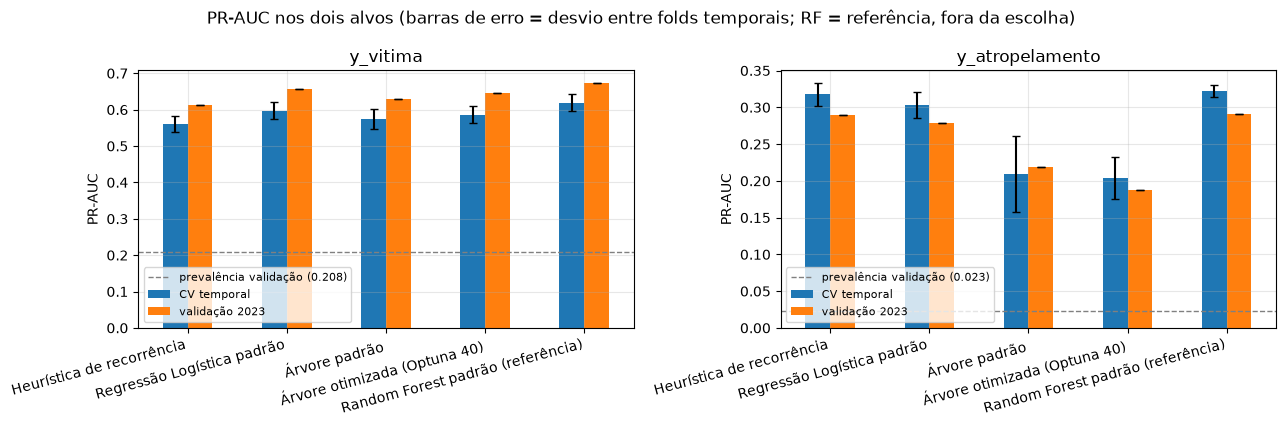

In [34]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, alvo, prev in [(axs[0], ALVO, yv.mean()), (axs[1], ALVO2, yv2.mean())]:
    vals = pd.DataFrame({NOMES[n]: {"CV temporal": resultados[(alvo, n)]["cv_temporal_pr_auc_mean"],
                                    "validação 2023": resultados[(alvo, n)]["val_pr_auc"]} for n in ordem_tab}).T
    erro = pd.DataFrame({"CV temporal": [resultados[(alvo, n)]["cv_temporal_pr_auc_std"] for n in ordem_tab],
                         "validação 2023": 0}, index=vals.index)
    vals.plot.bar(ax=ax, yerr=erro, capsize=3)
    ax.axhline(prev, color="gray", ls="--", lw=1, label=f"prevalência validação ({prev:.3f})")
    ax.set(title=alvo, ylabel="PR-AUC")
    ax.legend(fontsize=8)
    plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
fig.suptitle("PR-AUC nos dois alvos (barras de erro = desvio entre folds temporais; RF = referência, fora da escolha)")
salvar(fig, "pr_auc_dois_alvos.png")

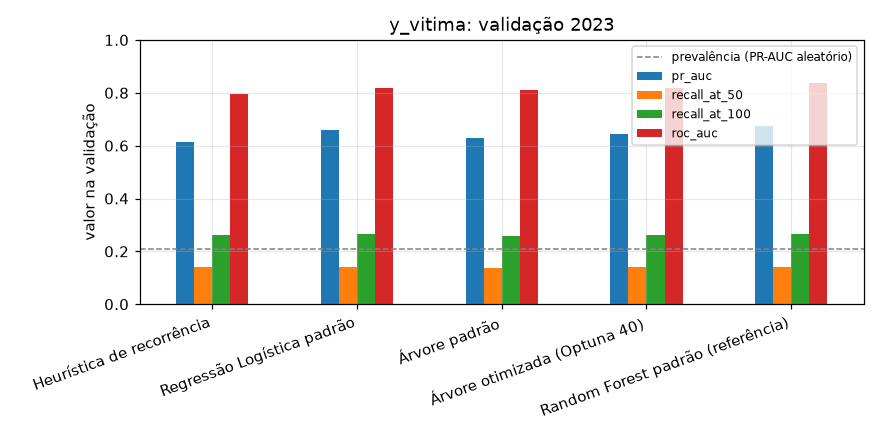

gravado: reports/experimentos/marina_arvore_decisao.csv | linhas: 10 | colunas: 27
runs no MLflow: {'arvore_decisao_padrao (y_vitima)': '7807c16dcd694c9cb8d069786409ba4d', 'arvore_decisao_optuna40_melhor (y_vitima)': 'fac4fb647a324e9888f15851a65b34ed', 'arvore_decisao_optuna40_melhor (y_atropelamento)': 'fdb65d7af4f449428460e083da949454'}
figuras: ['arvore_3_niveis.png', 'comparacao_validacao_y_vitima.png', 'curva_aprendizado.png', 'empates_degraus_score.png', 'empates_recall_at_k.png', 'importancia_impureza_x_permutacao.png', 'optuna_melhor_acumulado.png', 'optuna_pr_auc_por_hiperparametro.png', 'permutation_importance.png', 'pr_auc_dois_alvos.png', 'pr_auc_por_fold.png', 'pr_auc_treino_validacao.png', 'sensibilidade_semente.png', 'vies_variancia_max_depth.png', 'vies_variancia_min_samples_leaf.png']


In [35]:
# mesmas colunas do marina_mlp.csv (branch ml/mlp), na mesma ordem
colunas_csv = ["cv_temporal_pr_auc_mean", "cv_temporal_pr_auc_std", "cv_temporal_roc_auc_mean", "cv_temporal_roc_auc_std",
               "cv_estratificado_pr_auc_mean", "cv_estratificado_pr_auc_std", "val_pr_auc", "val_recall_at_50",
               "val_recall_at_100", "val_roc_auc", "val_prevalencia", "val_limiar", "val_f1", "val_precisao", "val_recall"]
CONFIG = {"heuristica_recorrencia": "heuristica_recorrencia", "regressao_logistica": "regressao_logistica",
          "arvore_padrao": "arvore_decisao_padrao", "arvore_otimizada": "arvore_decisao_otimizada",
          "random_forest_referencia": "random_forest_padrao_referencia"}
PARAMS = {"heuristica_recorrencia": "acidentes_vitima_4t + acidentes_4t/1000", "regressao_logistica": "pipeline.modelos()",
          "arvore_padrao": "pipeline.modelos()", "arvore_otimizada": str(params_melhor),
          "random_forest_referencia": "pipeline.modelos() (referência, fora da escolha)"}
csv = pd.DataFrame([{"autor": AUTOR, "modelo_investigado": MODELO, "alvo": a, "configuracao": CONFIG[n],
                     **{c: resultados[(a, n)].get(c) for c in colunas_csv},
                     "params": PARAMS[n], "run_id_mlflow": resultados[(a, n)].get("run_id"),
                     "tempo_busca_optuna_s": round(tempo_busca, 1), "n_trials_optuna": n_feitos,
                     "val_precisao_at_50": resultados[(a, n)]["val_precisao_at_50"],
                     "val_precisao_at_100": resultados[(a, n)]["val_precisao_at_100"],
                     "val_teto_recall_at_50": TETO[(a, 50)], "val_teto_recall_at_100": TETO[(a, 100)]}
                    for a in (ALVO, ALVO2) for n in ordem_tab])
csv.to_csv(EXP / f"{AUTOR}_{MODELO}.csv", index=False)

barras = pd.DataFrame({NOMES[n]: {k.removeprefix("val_"): resultados[(ALVO, n)][k] for k in
                                  ["val_pr_auc", "val_recall_at_50", "val_recall_at_100", "val_roc_auc", "val_prevalencia"]}
                       for n in ordem_tab}).T
metricas.barras_comparacao(barras, FIG / "comparacao_validacao_y_vitima.png", f"{ALVO}: validação 2023")
display(Image(FIG / "comparacao_validacao_y_vitima.png"))
print("gravado:", (EXP / f"{AUTOR}_{MODELO}.csv").relative_to(RAIZ), "| linhas:", len(csv), "| colunas:", len(csv.columns))
print("runs no MLflow:", {"arvore_decisao_padrao (y_vitima)": run_padrao, "arvore_decisao_optuna40_melhor (y_vitima)": run_otim,
                          "arvore_decisao_optuna40_melhor (y_atropelamento)": run_otim2})
print("figuras:", sorted(p.name for p in FIG.glob("*.png")))

A Tabela 2 junta os dois alvos. A linha do Random Forest está marcada como **referência**: ele não
participa da escolha nem foi otimizado. O CSV `reports/experimentos/marina_arvore_decisao.csv` tem uma
linha por alvo e por configuração (10 linhas), com as mesmas 27 colunas do `marina_mlp.csv`, e a
coluna `configuracao` identifica a linha de referência (`random_forest_padrao_referencia`). No
MLflow ficam três runs com `autor=marina` e `modelo=arvore_decisao`: `arvore_decisao_padrao`
(`02_comparacao_modelos`, `y_vitima`) e `arvore_decisao_optuna40_melhor` (`03_otimizacao_hiperparametros`,
`busca=optuna_40`) nos dois alvos.

## Conclusões

1. **Contra a Regressão Logística: a árvore perde, por pouco e de forma consistente.** A árvore
   otimizada (`max_depth=8`, `min_samples_leaf=125`) tem PR-AUC de 0,586 ± 0,024 na CV temporal e de
   0,645 na validação de 2023, contra 0,597 e 0,658 (−0,011 e −0,013). Ela perde nos quatro folds
   (−0,007 a −0,016), e a semente não muda a CV. No topo da lista a distância é pequena: Recall@50 de
   0,140 contra 0,141, precisão@50 de 0,960 contra 0,965 e precisão@100 de 0,900 contra 0,907. A
   árvore padrão fica mais longe (0,574 e 0,628).
2. **Contra a heurística de recorrência: ganho real, mas modesto.** +0,026 na CV (0,586 contra 0,560)
   e +0,031 na validação (0,645 contra 0,614), em todos os folds (+0,018 a +0,036). A árvore padrão
   ganha +0,014 e perde em 2022Q1.
3. **Contra o Random Forest de referência: o ensemble é claramente melhor.** O Random Forest padrão,
   sem otimização, tem 0,619 na CV e 0,674 na validação: +0,033 e +0,029 sobre a melhor árvore, em
   todos os folds. A média de 300 árvores permite folhas de 10 linhas, que numa árvore só sobreajustam.
   No atropelamento, ela também derruba o desvio entre folds (de 0,028 para 0,009).
4. **Busca e viés × variância.** Os 40 trials levaram 27,4 s. Eles ganharam +0,0057 na CV sobre os 10
   trials do repositório (6,7 s) e +0,011 na validação. O melhor ponto não encosta na borda do espaço
   (`max_depth` a 0,60, `min_samples_leaf` a 0,79 em escala log), e o espaço não foi ampliado. Quem
   regulariza a árvore é o `min_samples_leaf`. Com ~125 linhas por folha, a profundidade deixa de
   importar a partir de 7 ou 8. Abaixo de ~75 linhas por folha, o sobreajuste aparece. Com 5 linhas,
   ele começa na profundidade 6, e sem limite a CV cai para 0,397 (treino 0,887).
5. **Empates.** A árvore só produz um score por folha (58 valores distintos na validação). Em
   `y_vitima`, isso quase não afeta a melhor configuração (Recall@50 de 0,138 a 0,141), porque a
   folha do corte do 50º é quase só de positivos. Na árvore padrão, a ordem dos empatados explica toda
   a diferença de Recall@50 para os pisos (0,129 a 0,141). No atropelamento, o Recall@50 da árvore vai
   de 0,264 a 0,418 conforme o desempate. Comparações de Recall@k entre modelos de árvore precisam
   mostrar essa faixa.
6. **O que a árvore ensina sobre o problema.** O risco de acidente com vítima é, antes de tudo,
   **recorrência**. `rel_acidentes_4t` responde por 72% da impureza e 70% da importância por
   permutação. O primeiro corte (até ~1 acidente no último ano) separa 81,1% das linhas, com taxa de
   7,2%, dos 18,9% restantes, com 47,9% (no treino). Locais com 10 ou mais acidentes no ano tiveram
   acidente com vítima no trimestre seguinte em 85% a 98% dos casos no treino e em 94% a 97% em 2023.
   As regras se mantêm em 2023 (Spearman de 0,873 entre as taxas das folhas), e as 5 folhas de maior
   risco cobrem 6,4% das linhas, com taxa de 0,899. O perfil do local (madrugada, caminhão, ônibus, fim
   de semana) só refina a faixa intermediária. O limite também é claro: 56,3% dos falsos negativos vêm
   de locais sem nenhum acidente nos 4 trimestres anteriores, e nenhuma regra de recorrência os
   alcança.
7. **Alvo secundário.** No `y_atropelamento`, a árvore não serve. A CV é de 0,204 ± 0,028 contra 0,318
   da heurística, e a validação de 0,187 contra 0,290, com a ressalva dos ~40 positivos por trimestre
   e de a configuração ter vindo de `y_vitima`.
8. **Recomendações ao grupo.**
   - Não escolher a árvore como modelo de produção: a Regressão Logística é melhor nos dois alvos, e o
     Random Forest de referência é melhor ainda em `y_vitima`.
   - Usar a árvore como **camada de explicação**. As regras das folhas, traduzidas em nº de
     acidentes, dão à CTTU um critério simples e verificável ("10 ou mais acidentes no último ano →
     prioridade máxima"), que pode acompanhar o score do modelo escolhido no painel.
   - Não ampliar o espaço da árvore: o platô de 0,581 a 0,586 nos 10 melhores trials e as varreduras
     mostram que não há ganho a buscar ali.
   - Reportar a faixa de Recall@k sob empates sempre que um modelo tiver poucos scores distintos.
   - Para os falsos negativos sem histórico, o caminho é informação nova (telemetria, fluxo, obras),
     não outro modelo sobre as mesmas features.